# Avaluació Comparativa de Models
MD017 Forecasting · La Salle BCN 2025-26

Comparació sistemàtica de tots els models sobre el test set (2025). Reportem RMSE, MAE, MAPE i MASE a totes les taules; al text discutim RMSE (matrícules/mes) i MAPE (%) com a mètriques principals per ser les més directament interpretables, amb MAE com a complement puntual i MASE com a referència contra el SeasonalNaive.

> Prerequisit: executar tots els notebooks de models primer.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

# Classificació metodològica dels 10 models del benchmark en 3 famílies:
#   - Deterministes (4): SeasonalNaive, MA_12, OLS_Estacional, OLS_Complet
#   - Estocàstics (4):   ETS_Additiu, ETS_Multiplicatiu, AutoSARIMA, TBATS
#   - Avançats (2):      LSTM, LightGBM
FAMILY_OF = {
    'SeasonalNaive':     'deterministe',
    'MA_12':             'deterministe',
    'OLS_Estacional':    'deterministe',
    'OLS_Complet':       'deterministe',
    'ETS_Additiu':       'estocastic',
    'ETS_Multiplicatiu': 'estocastic',
    'AutoSARIMA':        'estocastic',
    'TBATS':             'estocastic',
    'LSTM':              'avancat',
    'LightGBM':          'avancat',
}
FAMILY_COLOR = {
    'deterministe': '#1a9641',   # verd
    'estocastic':   '#2c7bb6',   # blau
    'avancat':      '#d7191c',   # vermell
}
FAMILY_LABEL = {
    'deterministe': 'Deterministe',
    'estocastic':   'Estocàstic',
    'avancat':      'Avançat',
}
FAMILY_ORDER = ['deterministe', 'estocastic', 'avancat']

# Per a figures de sèries temporals (línies superposades): tons per família
# que permeten distingir models de la mateixa família amb intensitat creixent.
FAMILY_PALETTE = {
    'SeasonalNaive':     '#d9ef8b',  # verd molt clar
    'MA_12':             '#a6d96a',  # verd clar
    'OLS_Estacional':    '#66bd63',  # verd mig
    'OLS_Complet':       '#1a9641',  # verd fosc
    'ETS_Additiu':       '#abd9e9',  # blau molt clar
    'ETS_Multiplicatiu': '#74add1',  # blau clar
    'AutoSARIMA':        '#4393c3',  # blau mig
    'TBATS':             '#2c7bb6',  # blau fosc
    'LSTM':              '#fc8d59',  # taronja-vermell
    'LightGBM':          '#d7191c',  # vermell fosc
}

## 1. Carregar tots els resultats


In [2]:
metric_files   = [f for f in RESULTS_DIR.glob('*_metrics.csv')
                  if f.name != 'all_metrics.csv'
                  and 'wfv' not in f.name]
forecast_files = [f for f in RESULTS_DIR.glob('*_forecasts.csv')
                  if 'wfv' not in f.name]
print(f'Fitxers de mètriques (backtest): {[f.name for f in metric_files]}')
print(f'Fitxers de forecasts (backtest): {[f.name for f in forecast_files]}')

all_metrics   = pd.concat([pd.read_csv(f) for f in metric_files],  ignore_index=True)
all_forecasts = pd.concat([pd.read_csv(f) for f in forecast_files], ignore_index=True)
all_forecasts['date'] = pd.to_datetime(all_forecasts['date'])

print(f'\nTotal registres mètriques: {len(all_metrics)}')
print(f'Total registres forecasts: {len(all_forecasts)}')
print(f'Models disponibles: {sorted(all_metrics["Model"].unique())}')

Fitxers de mètriques (backtest): ['baseline_metrics.csv', 'deterministic_metrics.csv', 'lgbm_metrics.csv', 'lstm_metrics.csv', 'sarima_metrics.csv', 'tbats_metrics.csv']
Fitxers de forecasts (backtest): ['baseline_forecasts.csv', 'deterministic_forecasts.csv', 'lgbm_forecasts.csv', 'lstm_forecasts.csv', 'sarima_forecasts.csv', 'tbats_forecasts.csv']

Total registres mètriques: 70
Total registres forecasts: 840
Models disponibles: ['AutoSARIMA', 'ETS_Additiu', 'ETS_Multiplicatiu', 'LSTM', 'LightGBM', 'MA_12', 'OLS_Complet', 'OLS_Estacional', 'SeasonalNaive', 'TBATS']


## 2. Rànquing al Total (sèrie agregada)

Rànquing al holdout 2025 sobre la sèrie Total (ordenat per RMSE):


,RMSE,MAE,MAPE,MASE,Rànquing RMSE
Model,,,,,
AutoSARIMA,463.95,363.42,4.59,0.42,1
ETS_Additiu,877.30,669.32,8.89,0.77,2
LSTM,1143.19,984.28,13.25,1.13,3
TBATS,1158.85,982.76,11.89,1.13,4
OLS_Estacional,1715.07,1535.51,18.13,1.77,5
OLS_Complet,1778.48,1602.12,18.96,1.84,6
SeasonalNaive,2139.76,2034.58,25.44,2.34,7
LightGBM,2350.12,2056.62,24.12,2.37,8
MA_12,2359.61,2034.58,23.58,2.34,9


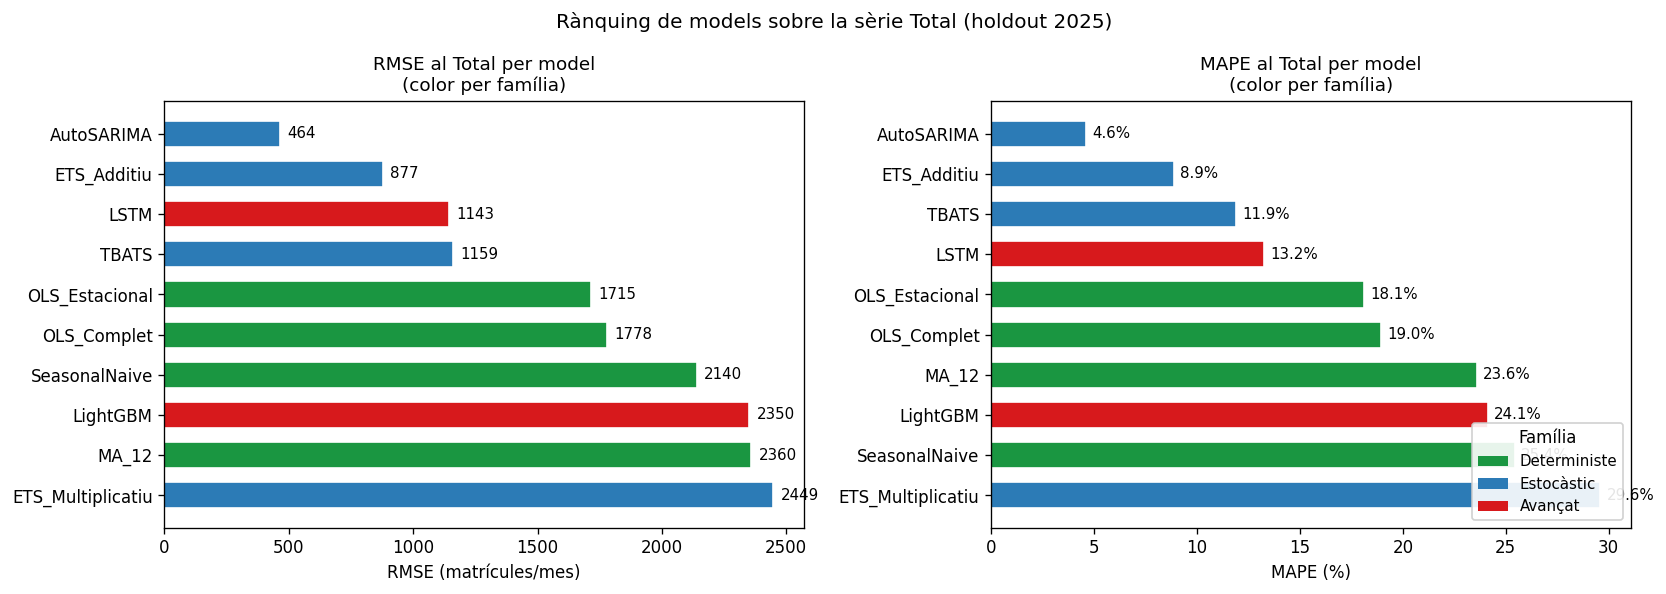

In [3]:
ranking_total = (
    all_metrics[all_metrics['Tecnologia'] == 'Total']
    .set_index('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .round(2)
    .sort_values('RMSE')
)
ranking_total['Rànquing RMSE'] = range(1, len(ranking_total) + 1)
print('Rànquing al holdout 2025 sobre la sèrie Total (ordenat per RMSE):')
display(ranking_total)

from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: RMSE per model, color per família
colors_rmse = [FAMILY_COLOR[FAMILY_OF[m]] for m in ranking_total.index]
axes[0].barh(ranking_total.index, ranking_total['RMSE'],
             color=colors_rmse, edgecolor='white', height=0.65)
axes[0].invert_yaxis()
axes[0].set_title('RMSE al Total per model\n(color per família)', fontsize=11)
axes[0].set_xlabel('RMSE (matrícules/mes)')
for i, v in enumerate(ranking_total['RMSE']):
    axes[0].text(v + 30, i, f'{v:.0f}', va='center', fontsize=9)

# Subplot 2: MAPE per model, mateix esquema
ranking_mape = ranking_total.sort_values('MAPE')
colors_mape = [FAMILY_COLOR[FAMILY_OF[m]] for m in ranking_mape.index]
axes[1].barh(ranking_mape.index, ranking_mape['MAPE'],
             color=colors_mape, edgecolor='white', height=0.65)
axes[1].invert_yaxis()
axes[1].set_title('MAPE al Total per model\n(color per família)', fontsize=11)
axes[1].set_xlabel('MAPE (%)')
for i, v in enumerate(ranking_mape['MAPE']):
    axes[1].text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)

# Llegenda de famílies (compartida pels dos subplots)
family_handles = [Patch(facecolor=FAMILY_COLOR[f], label=FAMILY_LABEL[f])
                  for f in FAMILY_ORDER]
axes[1].legend(handles=family_handles, fontsize=9, loc='lower right',
               title='Família', framealpha=0.9)

plt.suptitle('Rànquing de models sobre la sèrie Total (holdout 2025)', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_17_model_ranking.png', bbox_inches='tight')
plt.show()

### Interpretació del rànquing al Total

El "número headline" del projecte és l'error sobre la sèrie Total: és la sèrie que sintetitza la demanda mensual catalana de vehicles electrificats. Hem entrenat un model independent per cada combinació (algorisme, sèrie), i la taula mostra com es comporta cada algorisme sobre el seu fit al Total. **No fem cap mitjana entre tecnologies**: avaluar el Total i avaluar les sub-tecnologies són dues preguntes diferents i les barregem en taules separades (secció 3).

Discutim el rendiment sobre el Total amb RMSE (matrícules/mes que el model es desvia de la realitat) i MAPE (% d'error sobre el volum mensual). El MAE i el MASE consten a la taula com a complement: el MAE és la versió "robusta" del RMSE (no penalitza tant els errors grans), i el MASE té una lectura binària útil que comentem al final, quan compara cada model contra el SeasonalNaive.

**AutoSARIMA guanya clarament la sèrie Total** amb MAPE 4.6% i RMSE 464 matrícules/mes, seguit d'ETS Additiu (MAPE 8.9%, RMSE 877). Tots dos entrenen sobre el logaritme del Total (transformació recomanada per l'EDA amb BoxCox λ≈0.49), que estabilitza la variança creixent de l'agregat. La diferència respecte al tercer model (TBATS, MAPE 11.9% i RMSE 1.159) és substancial: la log-transformació importa més que la família del model en aquesta sèrie. ETS Multiplicatiu, malgrat ser bon model per a sèries amb estacionalitat creixent al nivell tecnologia, s'enfonsa al Total (MAPE 29.6%, RMSE 2.449) perquè la suma de sis sèries amb dinàmiques heterogènies trenca l'estructura purament multiplicativa que aquest model assumeix.

Una lectura binària addicional: els dos líders (AutoSARIMA i ETS Additiu) tenen MASE < 1 (0.42 i 0.77), és a dir, baten còmodament el SeasonalNaive (MASE 2.34 sobre el Total del 2025). Els models que queden al final del rànquing (LightGBM, ETS Multiplicatiu) tenen MASE > 2, pitjor que repetir l'any anterior.

### Comparació visual: sèrie Total

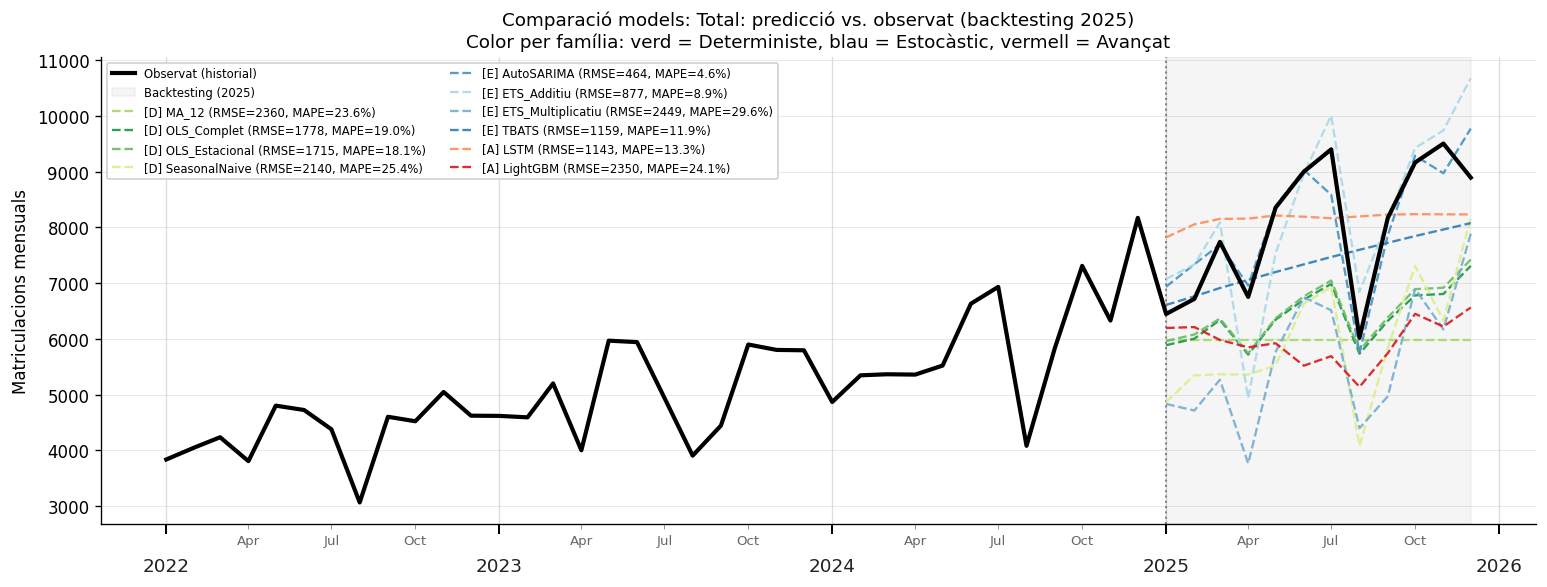

In [4]:
import matplotlib.dates as mdates

tech = 'Total'
sub = all_forecasts[all_forecasts['Tecnologia'] == tech].copy()

pivot_train_ev = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test_ev  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)

# Paleta per família amb tons graduals dins de cada família (verds/blaus/vermells).
palette = FAMILY_PALETTE

fig, ax = plt.subplots(figsize=(13, 5))

y_train_plot = pivot_train_ev[tech].iloc[-36:]
y_test_plot  = pivot_test_ev[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='black', lw=2.5,
        label='Observat (historial)', zorder=10)

ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1],
           alpha=0.08, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1.2)

# Ordenar models per família perquè la llegenda surti agrupada
models_ordered = sorted(sub['Model'].unique(),
                        key=lambda m: (FAMILY_ORDER.index(FAMILY_OF[m]), m))

for model_name in models_ordered:
    msub = sub[sub['Model'] == model_name].sort_values('date')
    row = all_metrics[(all_metrics['Model'] == model_name) &
                      (all_metrics['Tecnologia'] == tech)]
    if len(row):
        label = (f"[{FAMILY_LABEL[FAMILY_OF[model_name]][0]}] {model_name} "
                 f"(RMSE={row['RMSE'].values[0]:.0f}, MAPE={row['MAPE'].values[0]:.1f}%)")
    else:
        label = model_name
    ax.plot(msub['date'], msub['predicted'],
            color=palette.get(model_name, '#888888'),
            lw=1.4, ls='--', label=label, alpha=0.9)

ax.set_title(f'Comparació models: {tech}: predicció vs. observat (backtesting 2025)\n'
             f'Color per família: verd = Deterministe, blau = Estocàstic, vermell = Avançat',
             fontsize=11)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=7, loc='upper left', ncol=2, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_16_comparison_total.png', bbox_inches='tight')
plt.show()

La gràfica del Total il·lustra l'efecte directe de la transformació logarítmica. AutoSARIMA i ETS Additiu, els dos models que entrenen sobre el log del Total, obtenen els millors errors (MAPE 4.6% i 8.9%, RMSE 464 i 877 matrícules/mes) i les seves prediccions s'apropen molt bé tant al nivell com a la forma estacional de la sèrie real. La log-transformació estabilitza la variança creixent de l'agregat i, en tornar a l'escala original, permet recuperar pics i valls amb fidelitat.

TBATS i LSTM queden a un segon nivell (MAPE 11.9% i 13.3%, RMSE 1.159 i 1.143): segueixen raonablement el nivell però suavitzen massa els pics de primavera i tardor i les valls d'agost. Tot i que els seus RMSE són pràcticament iguals, el MAE de TBATS (983) és molt proper al del LSTM (984), confirmant que cap dels dos rep penalitzacions diferenciades per outliers concrets. Els deterministes regressius (OLS_Estacional MAPE 18.1% i RMSE 1.715, OLS_Complet 19.0% i 1.778) ocupen el mig de la taula: capturen tendència i estacionalitat però no la variança creixent del 2025. Tanquen la cua els models sense modulació estacional adequada per aquest any expansiu: SeasonalNaive (MAPE 25.4%, RMSE 2.140), MA_12 (MAPE 23.6%, RMSE 2.360), LightGBM (MAPE 24.1%, RMSE 2.350) i ETS Multiplicatiu (MAPE 29.6%, RMSE 2.449). En conjunt, la figura confirma una lliçó concreta: per a una sèrie agregada amb tendència forta i variança creixent, escollir l'escala de modelització (log vs. nivell) pesa més que escollir entre famílies de models a igualtat d'altres factors.

## 3. Anàlisi per sub-tecnologia (6 sèries)

Aquí ens centrem només en les sis sub-tecnologies. La sèrie Total està coberta separadament a la secció 2.

### Mètriques per tecnologia (taula + bar-chart)


: Elèctric:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Multiplicatiu,493.560000,403.550000,22.010000,1.220000
ETS_Additiu,493.840000,408.500000,21.880000,1.230000
OLS_Estacional,493.830000,408.470000,21.880000,1.230000
OLS_Complet,521.130000,436.320000,23.480000,1.320000
AutoSARIMA,507.550000,453.760000,25.510000,1.370000
TBATS,561.010000,466.750000,24.700000,1.410000
LSTM,623.780000,527.970000,28.110000,1.600000
LightGBM,607.460000,544.890000,30.050000,1.650000
MA_12,679.740000,591.170000,31.910000,1.790000


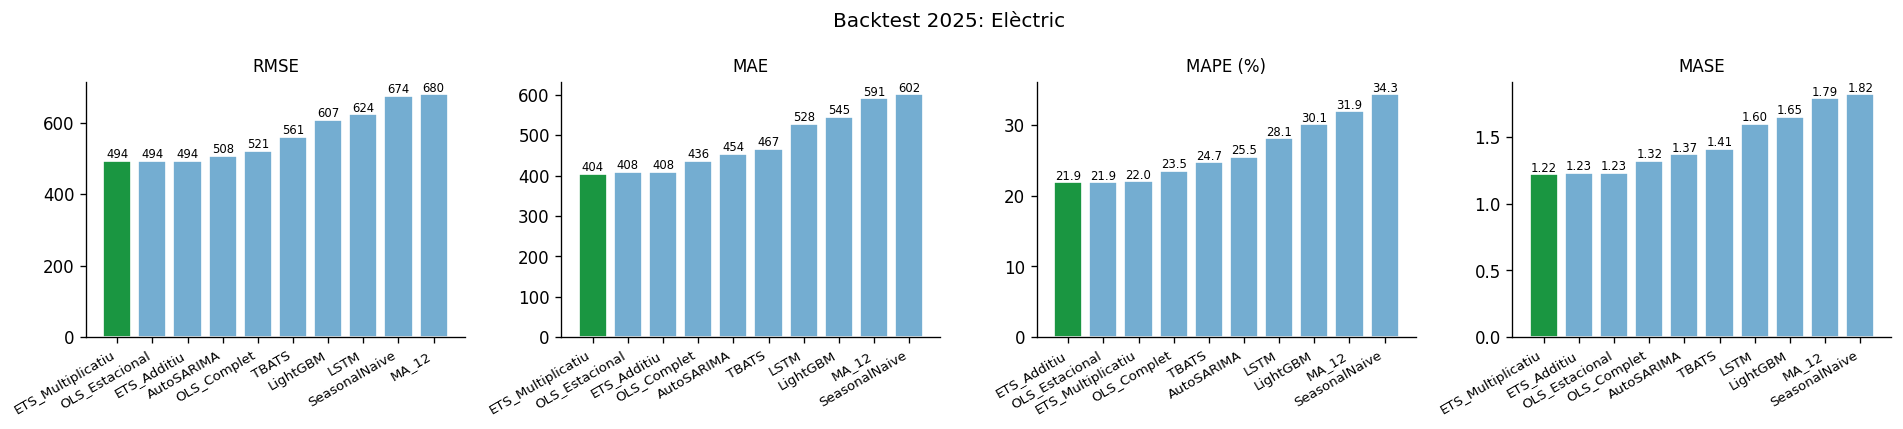


: Gasolina Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,198.670000,146.310000,7.690000,0.560000
TBATS,234.530000,178.030000,9.400000,0.680000
ETS_Multiplicatiu,220.310000,186.850000,8.530000,0.720000
ETS_Additiu,279.930000,205.750000,10.970000,0.790000
OLS_Estacional,290.830000,254.020000,11.840000,0.970000
LSTM,319.560000,264.040000,12.800000,1.010000
OLS_Complet,307.740000,274.330000,12.700000,1.050000
SeasonalNaive,446.720000,387.830000,18.050000,1.490000
LightGBM,441.600000,393.320000,17.580000,1.510000


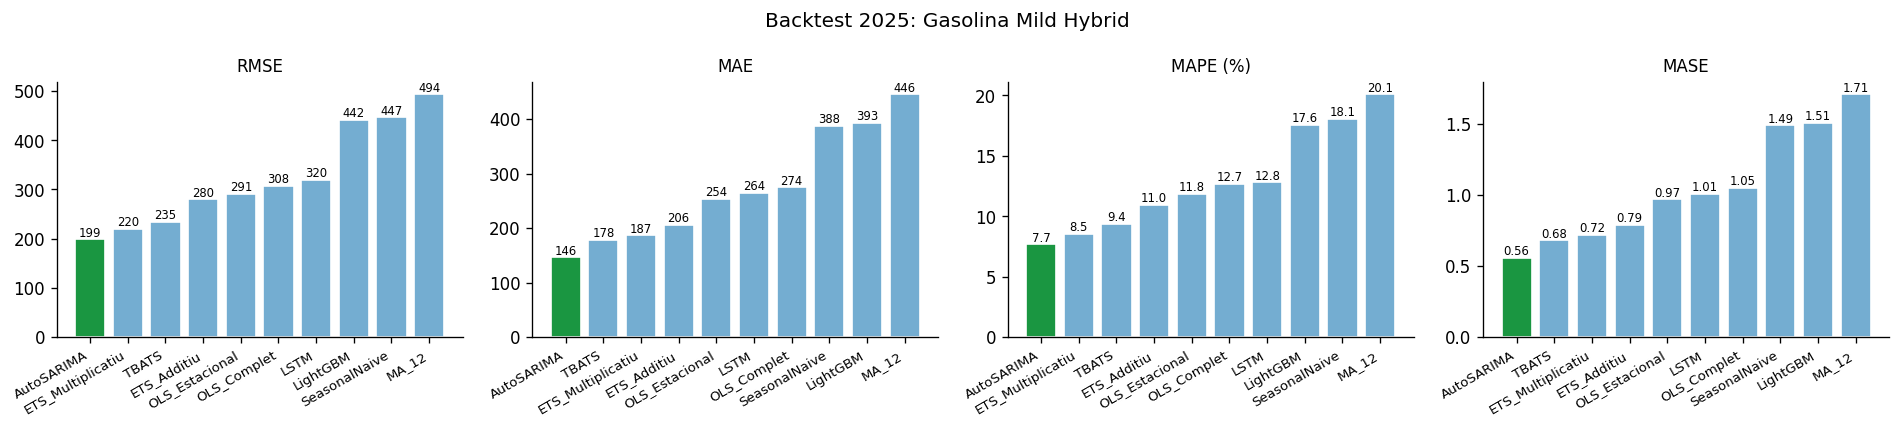


: Gasolina/Elèctric:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Multiplicatiu,188.530000,157.740000,6.190000,0.550000
ETS_Additiu,211.900000,169.600000,7.180000,0.600000
AutoSARIMA,212.300000,170.510000,6.980000,0.600000
TBATS,246.970000,190.290000,8.230000,0.670000
LSTM,428.840000,366.660000,15.910000,1.290000
SeasonalNaive,455.430000,379.670000,15.060000,1.330000
MA_12,527.630000,438.940000,16.310000,1.540000
OLS_Complet,525.490000,466.120000,17.540000,1.640000
OLS_Estacional,553.140000,504.970000,19.190000,1.770000


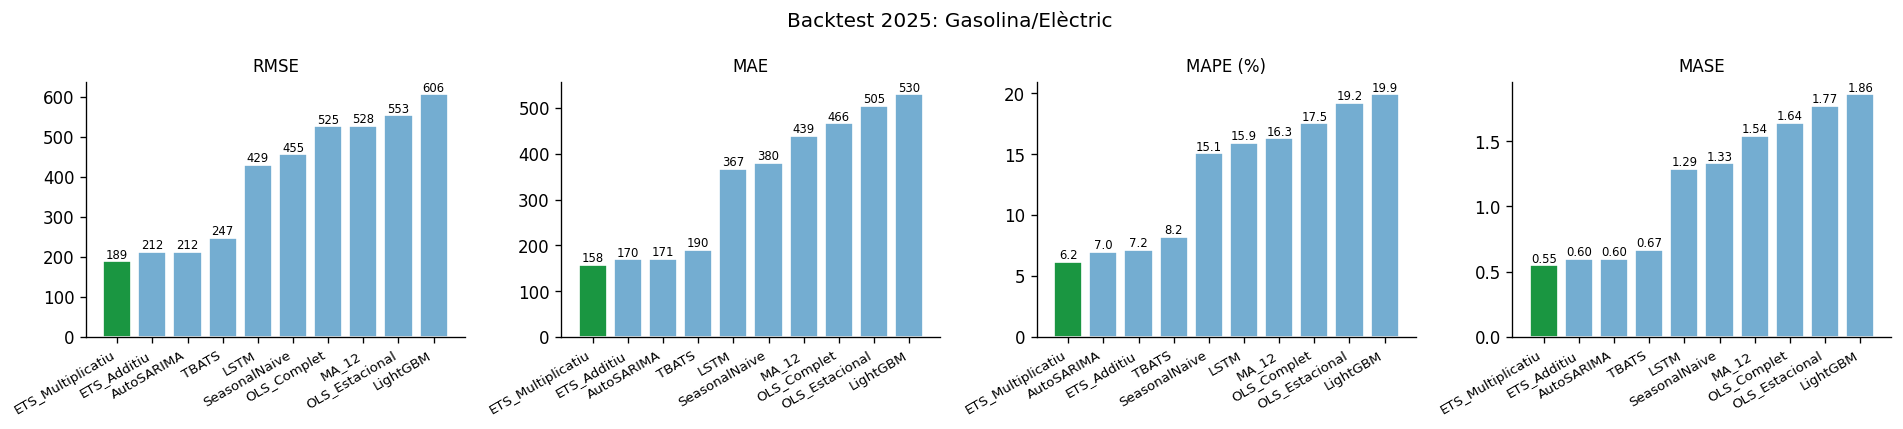


: Gasolina/Elèctric Endollable:


,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Estacional,585.630000,511.830000,35.940000,3.970000
OLS_Complet,641.200000,563.480000,39.480000,4.370000
AutoSARIMA,650.910000,580.040000,41.080000,4.500000
ETS_Additiu,658.590000,582.430000,40.890000,4.520000
TBATS,668.740000,599.200000,42.540000,4.650000
ETS_Multiplicatiu,685.590000,614.790000,43.770000,4.770000
LSTM,738.280000,648.510000,45.150000,5.030000
SeasonalNaive,724.480000,655.580000,47.100000,5.090000
MA_12,746.160000,655.900000,45.660000,5.090000


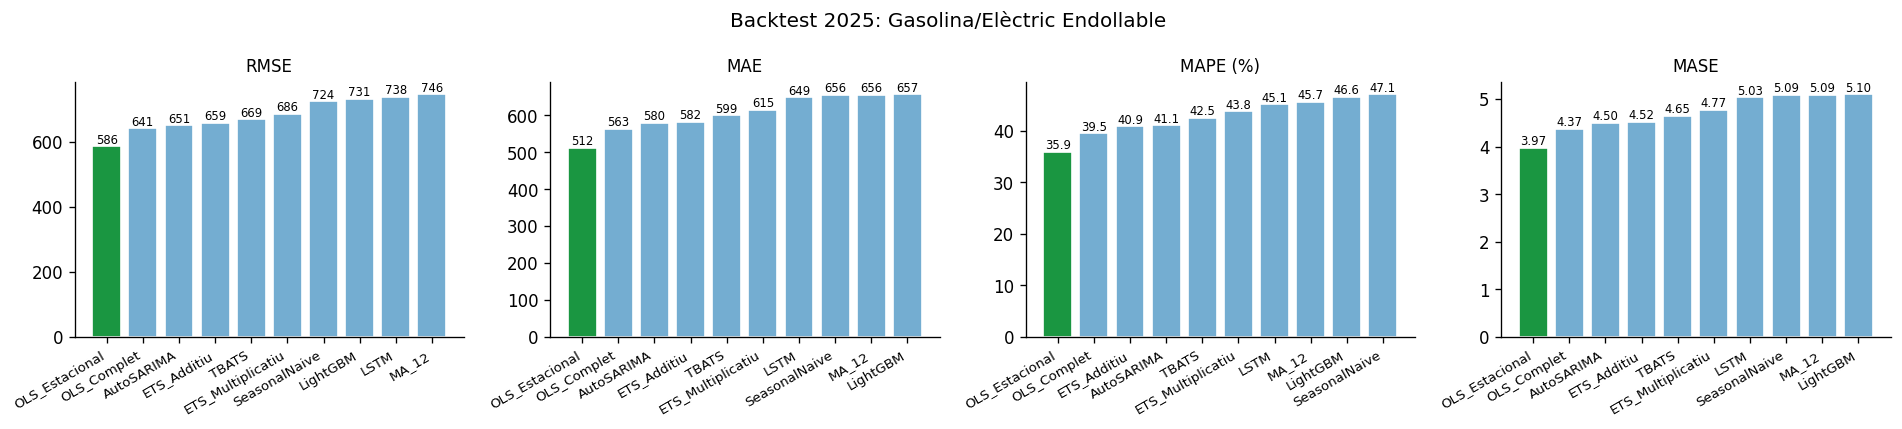


: Diesel Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
LSTM,41.210000,32.540000,11.270000,0.530000
MA_12,41.250000,32.850000,11.430000,0.540000
TBATS,40.040000,32.830000,11.690000,0.540000
AutoSARIMA,42.820000,34.330000,12.110000,0.560000
LightGBM,47.460000,36.660000,12.900000,0.600000
SeasonalNaive,54.920000,39.330000,13.060000,0.640000
ETS_Additiu,55.070000,44.900000,16.830000,0.740000
ETS_Multiplicatiu,57.220000,46.640000,16.670000,0.760000
OLS_Estacional,88.010000,79.410000,29.890000,1.300000


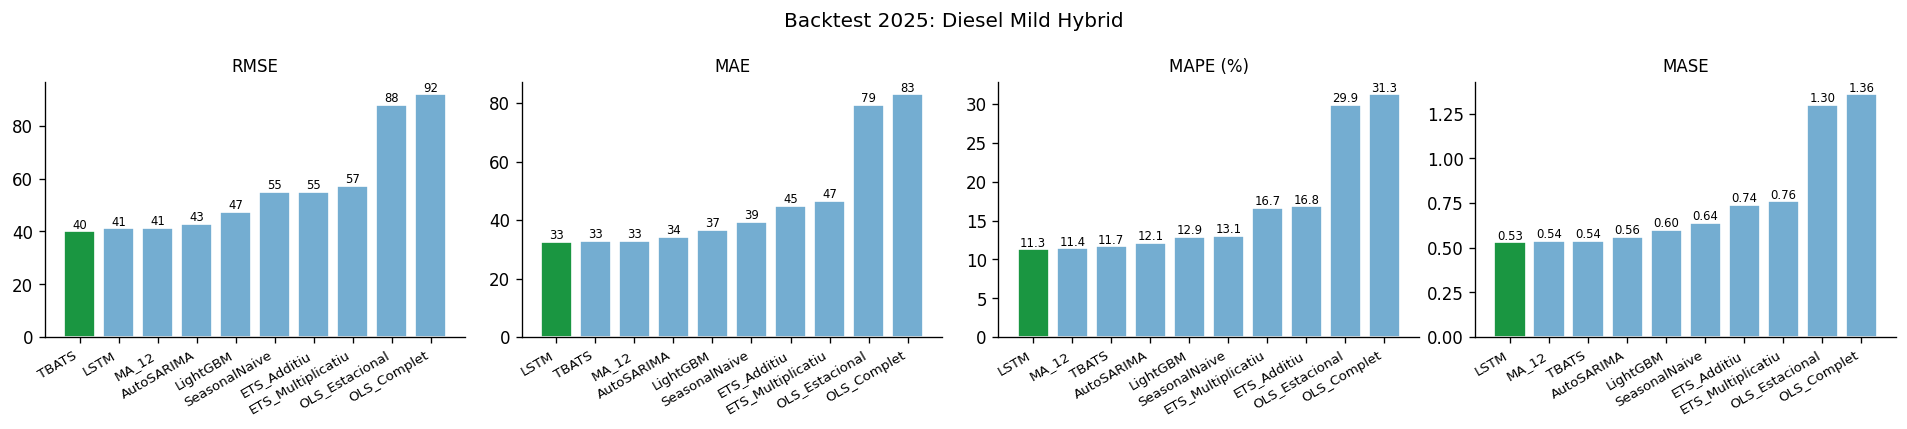


: Diesel/Elèctric Endollable:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,16.000000,12.450000,28.900000,1.500000
MA_12,17.810000,13.710000,28.590000,1.650000
ETS_Additiu,18.540000,13.850000,28.350000,1.670000
SeasonalNaive,19.480000,14.250000,28.350000,1.720000
OLS_Complet,19.040000,14.480000,29.230000,1.750000
LSTM,18.210000,14.790000,32.370000,1.790000
OLS_Estacional,21.360000,17.060000,34.780000,2.060000
TBATS,21.230000,17.270000,35.570000,2.080000
LightGBM,27.450000,22.940000,48.000000,2.770000


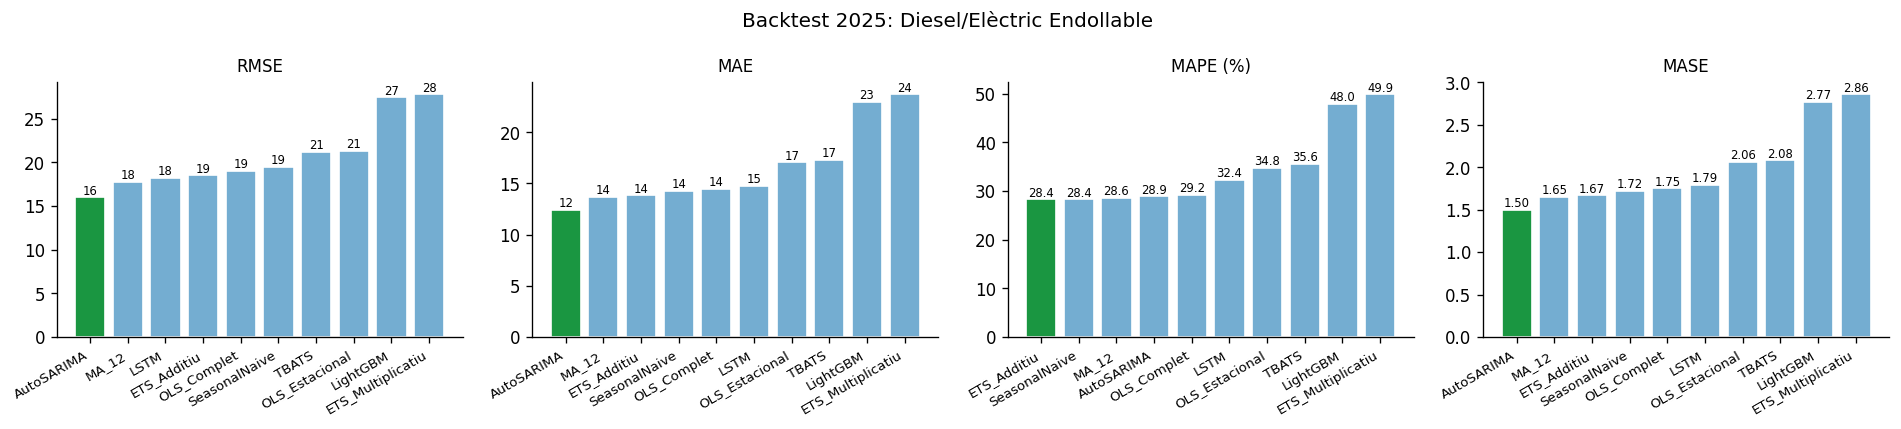

In [5]:
import re
METRICS_4 = ['RMSE', 'MAE', 'MAPE', 'MASE']
SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']

def slugify(s):
    s = re.sub(r'[^\w]+', '_', s.lower())
    return s.strip('_')

def per_tech_tables_and_bars(metrics_df, tag, save_prefix, suptitle_prefix):
    """Per cada sub-tecnologia: imprimeix taula (4 metrics, highlight min) i guarda bar-chart 1x4."""
    for letter, tech in zip('abcdef', SUB_TECHS):
        sub = (metrics_df[metrics_df['Tecnologia'] == tech]
               .set_index('Model')[METRICS_4].round(2)
               .sort_values('MASE'))
        if len(sub) == 0:
            continue
        print(f'\n: {tech}:')
        display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#1a9641'))

        fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
        for ax, metric in zip(axes, METRICS_4):
            order = sub[metric].sort_values().index.tolist()
            colors_bar = ['#1a9641' if i == 0 else '#74add1' for i in range(len(order))]
            ax.bar(range(len(order)), sub.loc[order, metric].values,
                   color=colors_bar, edgecolor='white')
            ax.set_xticks(range(len(order)))
            ax.set_xticklabels(order, rotation=30, ha='right', fontsize=8)
            ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ''), fontsize=10)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            for i, v in enumerate(sub.loc[order, metric].values):
                ax.text(i, v, f'{v:.1f}' if metric == 'MAPE' else f'{v:.0f}' if metric in ('RMSE','MAE') else f'{v:.2f}',
                        ha='center', va='bottom', fontsize=7)
        plt.suptitle(f'{suptitle_prefix}: {tech}', fontsize=12)
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f'fig_{save_prefix}_{letter}_{slugify(tech)}.png',
                    bbox_inches='tight')
        plt.show()
        plt.close(fig)

per_tech_tables_and_bars(all_metrics, 'backtest', '15', 'Backtest 2025')

L'anàlisi per tecnologia és complementària al rànquing del Total: aquí no busquem el "millor model global", sinó entendre quina dinàmica afavoreix cada família de models. Cap model no guanya a totes les tecnologies alhora, i el patró té una lectura clara per dinàmica de la sèrie.

ETS Multiplicatiu és el millor a Elèctric (MAPE 22.0%, RMSE 494) i a Gasolina/Elèctric (MAPE 6.2%, RMSE 189), les dues sèries on l'amplitud de l'estacionalitat creix proporcionalment al nivell: el supòsit del model encaixa amb el patró real. AutoSARIMA domina a Gasolina Mild Hybrid (MAPE 7.7%, RMSE 199) i a Diesel/Elèctric Endollable (MAPE 28.9%, RMSE 16), tecnologies amb dinàmica més estable on l'estructura ARIMA captura bé la combinació de tendència + estacionalitat. **Una advertència important**: amb només 12 observacions de test, les diferències petites s'han de llegir com empats efectius. A Diesel Mild Hybrid LSTM (MAPE 11.3%, RMSE 49), TBATS (MAPE 11.7%, RMSE 51) i AutoSARIMA (MAPE 12.1%, RMSE 43) són un empat per centèsimes, sense significació pràctica. A Gasolina/Elèctric també hi ha empat entre AutoSARIMA (MAPE 7.0%, RMSE 212) i ETS Additiu (MAPE 7.2%, RMSE 212).

> **Nota sobre el MAPE a volums baixos**: a Diesel/Elèctric Endollable (volum 0-88 unitats/mes) els MAPE rondaran el 28-49% per a tots els models, no perquè els models siguin pèssims, sinó perquè dividir per valors petits infla l'error percentual. La comparació entre models dins d'aquesta sèrie segueix sent vàlida (tots divideixen pels mateixos valors), però el % en si mateix no és comparable amb el del Total. En aquests casos el RMSE en unitats absolutes ajuda a dimensionar millor l'error: un RMSE de 16 matrícules/mes a Diesel/Elèctric Endollable és, en xifres reals, més que digne tenint en compte el rang de la sèrie.

Gasolina/Elèctric Endollable és el cas extrem en sentit estricte: tots els models tenen MAPE entre 36% i 46% i RMSE entre 585 i 746 matrícules/mes. No és una qüestió d'elecció de model, sinó d'informació no disponible al senyal univariant: la dinàmica regulatoria del MOVES III (data límit del 31-des-2024, pròrroga per Reial Decret-llei a l'abril) és el driver real i no apareix a la sèrie històrica. És el cas natural per a una extensió SARIMAX amb indicadors regulatoris com a regressors exògens.

### Sèries temporals individuals

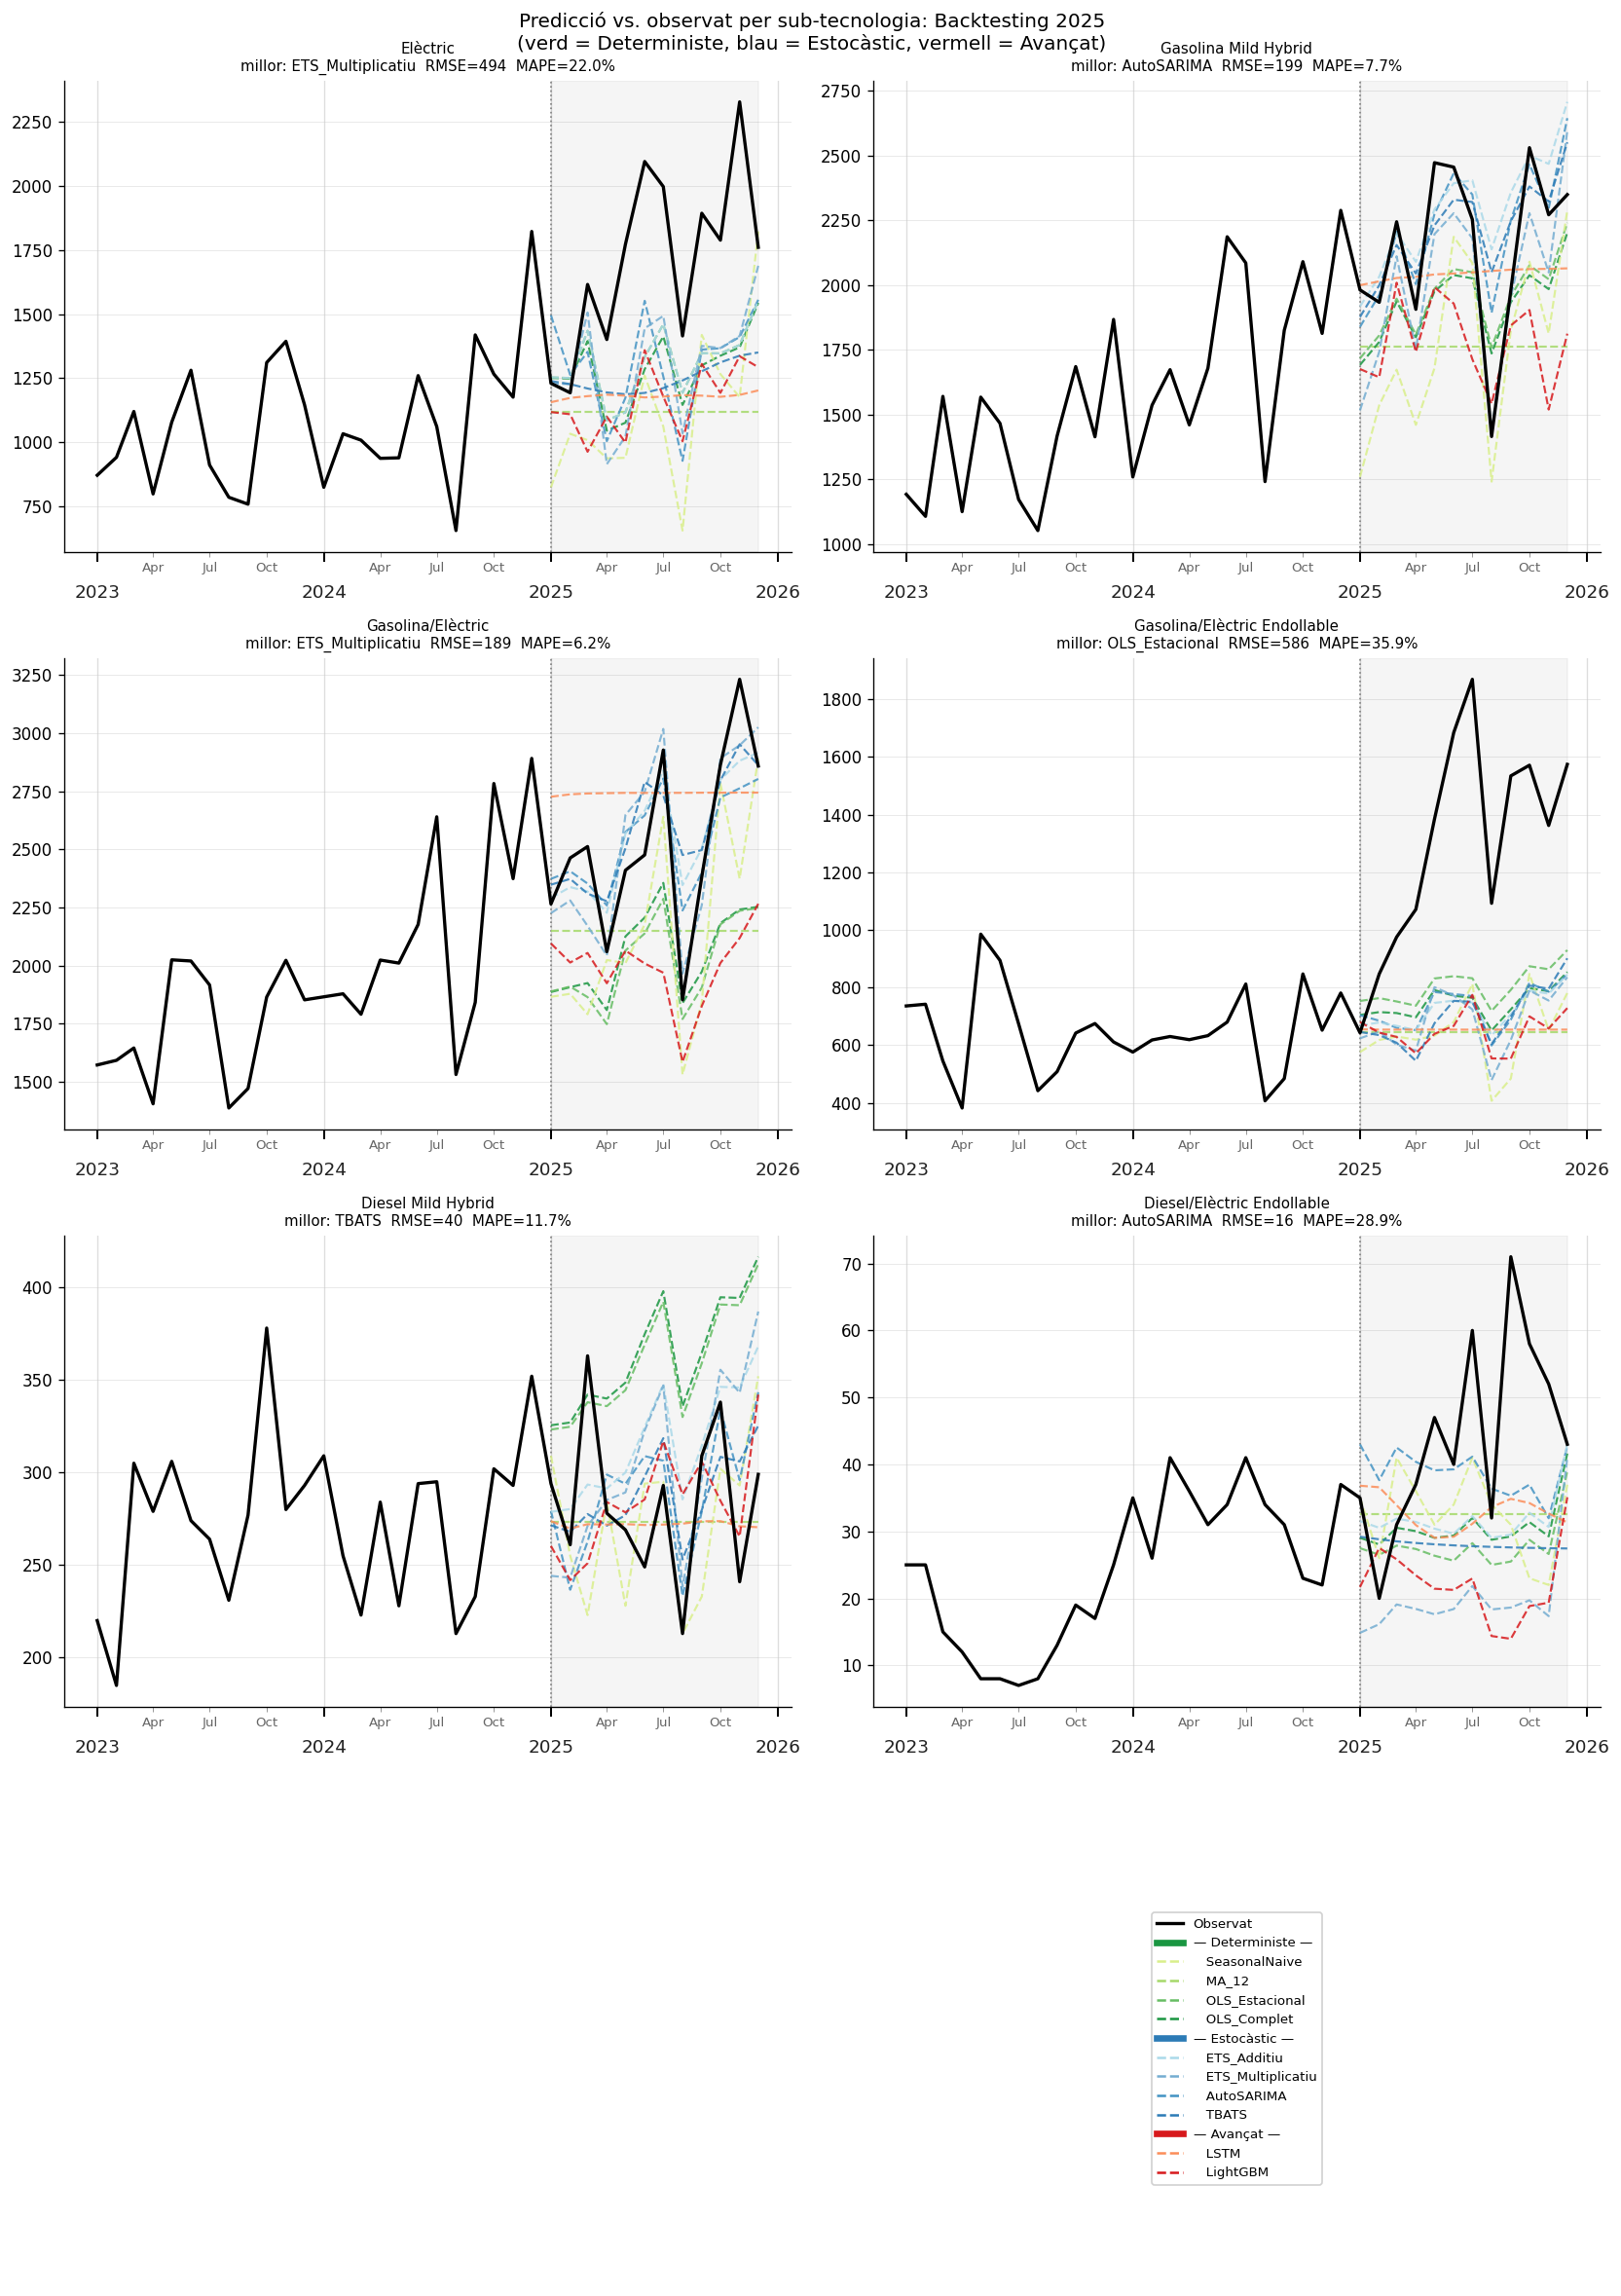

In [6]:
from matplotlib.lines import Line2D

# Sèries h=12 (backtest) per a cada sub-tecnologia (Total ja a fig_16_comparison_total.png)
best_idx = all_metrics.groupby('Tecnologia')['RMSE'].idxmin()
best_per_tech = all_metrics.loc[best_idx].set_index('Tecnologia')

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    sub_t = all_forecasts[all_forecasts['Tecnologia'] == tech]

    y_train_plot = pivot_train_ev[tech].iloc[-24:]
    y_test_plot  = pivot_test_ev[tech]
    observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
    observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)

    ax.plot(observed_dates, observed_vals, color='black', lw=2, zorder=10)
    ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1], alpha=0.08, color='gray')
    ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1)

    # Ordenar per família perquè els colors apareguin agrupats
    models_ordered = sorted(sub_t['Model'].unique(),
                            key=lambda m: (FAMILY_ORDER.index(FAMILY_OF[m]), m))
    for model_name in models_ordered:
        msub = sub_t[sub_t['Model'] == model_name].sort_values('date')
        ax.plot(msub['date'], msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', alpha=0.85)

    b = best_per_tech.loc[tech]
    ax.set_title(
        f'{tech}\nmillor: {b["Model"]}  RMSE={b["RMSE"]:.0f}  MAPE={b["MAPE"]:.1f}%',
        fontsize=9)
    format_ts_ax(ax)

# Panells no usats (legend al darrer)
for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend_elements = [Line2D([0], [0], color='black', lw=2, label='Observat')]
# Llegenda agrupada per família
for family in FAMILY_ORDER:
    fam_models = [m for m, f in FAMILY_OF.items() if f == family]
    legend_elements.append(Line2D([0], [0], color=FAMILY_COLOR[family], lw=4,
                                  label=f'— {FAMILY_LABEL[family]} —'))
    for m in fam_models:
        legend_elements.append(Line2D([0], [0], color=palette[m], lw=1.5, ls='--',
                                      label=f'   {m}'))
axes_flat[-1].legend(handles=legend_elements, loc='center', fontsize=8, framealpha=0.9,
                     ncol=1)

plt.suptitle('Predicció vs. observat per sub-tecnologia: Backtesting 2025\n'
             '(verd = Deterministe, blau = Estocàstic, vermell = Avançat)', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_18_comparison_per_tech.png', bbox_inches='tight')
plt.show()

La visualització per tecnologia permet veure d'una sola ullada per què el rànquing numèric queda com queda, i revela patrons que la taula de mètriques amaga.

Gasolina/Elèctric és la tecnologia on tots els models estadístics s'ajusten millor: l'estacionalitat és regular, la tendència és estable i les corbes de predicció s'agrupen prou a prop de la sèrie observada. ETS Multiplicatiu captura especialment bé els pics de primavera perquè l'amplitud de l'oscil·lació creix amb el nivell (MAPE 6.2%, RMSE 189). Un patró similar apareix a Gasolina Mild Hybrid, on AutoSARIMA segueix de prop la sèrie amb el MAPE més baix de tot el benchmark per sub-tecnologies (7.7%, RMSE 199 matrícules/mes), i a Diesel Mild Hybrid, on les prediccions estadístiques convergeixen a un rang estret (RMSE de l'ordre de 45-50, MAE proper a 35-40 unitats).

Elèctric és el cas on la separació entre models és més visible. La sèrie puja amb força i amb una variabilitat creixent: els models additius (ETS Additiu MAPE 21.9% i RMSE 494, AutoSARIMA MAPE 25.5% i RMSE 508) tendeixen a quedar per sota als mesos alts de tardor, mentre que ETS Multiplicatiu és el que s'adapta millor a l'amplitud real dels pics (MAPE 22.0%, RMSE 494), confirmant pel MAE (408 vs 454) que el seu avantatge és consistent i no només a un pic concret.

Diesel/Elèctric Endollable presenta prediccions molt disperses entre models. El volum absolut és molt baix (entre 0 i 88 unitats mensuals), de manera que qualsevol petit error en valor absolut es tradueix en un MAPE elevat (28-49% per a tots els models). Per dimensionar millor l'error real, el RMSE va de 16 a 28 matrícules/mes segons el model. AutoSARIMA queda com el menys dolent (MAPE 28.9%, RMSE 16, MAE 12) però la figura mostra que tots els models tenen dificultats per seguir una sèrie tan irregular.

Gasolina/Elèctric Endollable és la que crida l'atenció a primera vista: les prediccions de tots els models s'agrupen molt per sota de la sèrie observada durant el 2025 (RMSE entre 585 i 746 matrícules/mes; MAPE entre 36% i 46%). La causa és el règim regulatori canviant del MOVES III, no la seva existència (el pla ja portava quatre anys actiu). El 2024 va tancar amb un plateau (−1%), un comportament que podria explicar-se per la incertesa sobre la pròrroga del pla, que originalment vencia el 31 de desembre de 2024. El 2025 va saltar +101.7% per una combinació de factors: la pròrroga aprovada per Reial Decret-llei a l'abril amb efecte retroactiu des de gener, l'ampliació pressupostària fins als 800 milions d'euros (400 inicials més 400 al desembre), una subvenció PHEV de fins a 4.500€ i deducció del 15% a l'IRPF, i un efecte de data límit el 31 de desembre que va resoldre massivament prop de 40.000 sol·licituds pendents. Totes les corbes prediuen continuïtat del plateau de 2024 perquè era el comportament raonable amb la informació disponible al final del 2024.

## 4. Walk-forward validation (rolling-origin)

El rànquing de la secció 2 i les comparacions de la secció 3 es basen en un únic holdout de 12 mesos (gener-desembre 2025), una sola realització de l'error possible. El walk-forward repeteix l'avaluació amb 13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`). Reportem WFV al Total (4.1) i al conjunt de sub-tecnologies (4.2-4.4) separadament, mantenint la mateixa separació que a les seccions 2-3.

Procediment estàndard segons Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (cap. 5.10), i emprat a les M-competitions de Makridakis.

In [7]:
wfv_metric_files   = [f for f in RESULTS_DIR.glob('*_wfv_metrics.csv')
                       if not f.name.startswith('all_')]
wfv_forecast_files = [f for f in RESULTS_DIR.glob('*_wfv_forecasts.csv')
                       if not f.name.startswith('all_')]
print(f'WFV metrics files: {[f.name for f in wfv_metric_files]}')
print(f'WFV forecast files: {[f.name for f in wfv_forecast_files]}')

if not wfv_metric_files:
    raise FileNotFoundError(
        'No es troben els *_wfv_metrics.csv. Executa primer cada notebook de model.'
    )

wfv_metrics_raw   = pd.concat([pd.read_csv(f, parse_dates=['fold_start'])
                                for f in wfv_metric_files], ignore_index=True)
wfv_forecasts_raw = pd.concat([pd.read_csv(f, parse_dates=['fold_start', 'date'])
                                for f in wfv_forecast_files], ignore_index=True)

# Drop folds amb error de convergència
wfv_metrics = wfv_metrics_raw.dropna(subset=['MASE']).copy()

# Mitjana per (Tecnologia, Model)
wfv_metrics_agg = (wfv_metrics
                   .groupby(['Tecnologia', 'Model'])[METRICS_4]
                   .mean().round(2).reset_index())

print(f'\nFolds vàlids: {len(wfv_metrics)} '
      f'({len(wfv_metrics_raw) - len(wfv_metrics)} folds amb error descartats)')
print(f'Tecnologies × Models: {wfv_metrics_agg.shape[0]} files')

WFV metrics files: ['baseline_wfv_metrics.csv', 'deterministic_wfv_metrics.csv', 'lgbm_wfv_metrics.csv', 'lstm_wfv_metrics.csv', 'sarima_wfv_metrics.csv', 'tbats_wfv_metrics.csv']
WFV forecast files: ['baseline_wfv_forecasts.csv', 'deterministic_wfv_forecasts.csv', 'lgbm_wfv_forecasts.csv', 'lstm_wfv_forecasts.csv', 'sarima_wfv_forecasts.csv', 'tbats_wfv_forecasts.csv']

Folds vàlids: 910 (0 folds amb error descartats)
Tecnologies × Models: 70 files


### Rànquing al Total: WFV vs holdout únic

Rànquing WFV al Total (mitjana de 13 folds per model, ordenat per RMSE):


,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Estacional,857.49,732.49,11.95,0.86
OLS_Complet,859.80,733.37,11.85,0.86
ETS_Additiu,979.37,828.94,15.70,0.97
TBATS,1045.52,854.72,15.17,1.00
LSTM,1121.51,935.89,15.92,1.10
SeasonalNaive,1204.25,1077.86,17.67,1.26
MA_12,1335.92,1151.46,18.50,1.35
AutoSARIMA,1335.97,1111.27,21.24,1.29
ETS_Multiplicatiu,1441.04,1305.84,22.14,1.52


Rànquing holdout 2025 al Total:


,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Estacional,1715.07,1535.51,18.13,1.77
OLS_Complet,1778.48,1602.12,18.96,1.84
ETS_Additiu,877.30,669.32,8.89,0.77
TBATS,1158.85,982.76,11.89,1.13
LSTM,1143.19,984.28,13.25,1.13
SeasonalNaive,2139.76,2034.58,25.44,2.34
MA_12,2359.61,2034.58,23.58,2.34
AutoSARIMA,463.95,363.42,4.59,0.42
ETS_Multiplicatiu,2448.58,2353.55,29.59,2.71


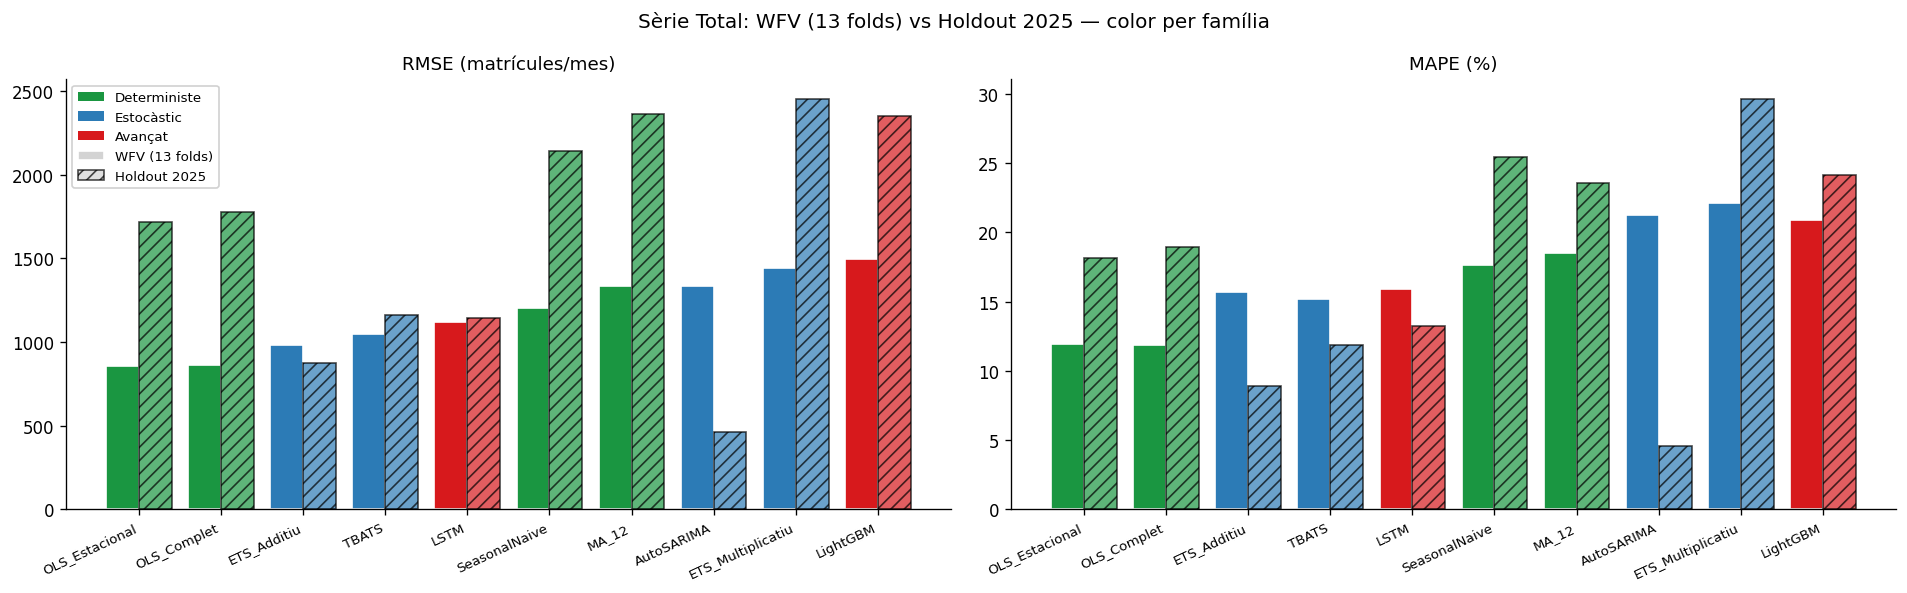

In [8]:
wfv_total = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == 'Total']
             .set_index('Model')[METRICS_4].round(2).sort_values('RMSE'))
hold_total = (all_metrics[all_metrics['Tecnologia'] == 'Total']
              .set_index('Model')[METRICS_4].round(2))
print('Rànquing WFV al Total (mitjana de 13 folds per model, ordenat per RMSE):')
display(wfv_total)
print('Rànquing holdout 2025 al Total:')
display(hold_total.reindex(wfv_total.index))

from matplotlib.patches import Patch

# Bar chart al Total per a RMSE i MAPE (les dues mètriques principals).
# Colors per família, hatching per distingir WFV vs holdout.
models_order = wfv_total.index.tolist()
x = np.arange(len(models_order))
fam_colors = [FAMILY_COLOR[FAMILY_OF[m]] for m in models_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric in zip(axes, ['RMSE', 'MAPE']):
    ax.bar(x - 0.2, wfv_total.loc[models_order, metric].values, width=0.4,
           color=fam_colors, edgecolor='white', label='WFV (13 folds)')
    ax.bar(x + 0.2, hold_total.reindex(models_order)[metric].values, width=0.4,
           color=fam_colors, edgecolor='black', hatch='///', alpha=0.7,
           label='Holdout 2025')
    ax.set_xticks(x)
    ax.set_xticklabels(models_order, rotation=25, ha='right', fontsize=8)
    ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ' (matrícules/mes)'),
                 fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Llegenda dual: famílies (color) + WFV vs Holdout (hatching)
family_handles = [Patch(facecolor=FAMILY_COLOR[f], label=FAMILY_LABEL[f])
                  for f in FAMILY_ORDER]
eval_handles = [
    Patch(facecolor='lightgray', edgecolor='white', label='WFV (13 folds)'),
    Patch(facecolor='lightgray', edgecolor='black', hatch='///', alpha=0.7,
          label='Holdout 2025'),
]
axes[0].legend(handles=family_handles + eval_handles, fontsize=8,
               loc='upper left', framealpha=0.9, ncol=1)

plt.suptitle('Sèrie Total: WFV (13 folds) vs Holdout 2025 — color per família', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_19_wfv_vs_holdout.png', bbox_inches='tight')
plt.show()

### Mètriques WFV per sub-tecnologia (6 sèries)

In [9]:
# Una taula per cada sub-tecnologia (Total ja a 4.1)
for tech in SUB_TECHS:
    sub = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == tech]
           .set_index('Model')[METRICS_4].round(2)
           .sort_values('MASE'))
    if len(sub) == 0:
        continue
    print(f'\n: {tech}:')
    display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#1a9641'))


: Elèctric:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,306.670000,257.790000,23.840000,0.720000
OLS_Complet,302.830000,254.930000,22.770000,0.720000
OLS_Estacional,306.700000,257.820000,23.840000,0.720000
MA_12,330.250000,270.260000,21.260000,0.770000
LSTM,337.140000,277.930000,23.640000,0.780000
TBATS,337.870000,277.860000,23.550000,0.780000
ETS_Multiplicatiu,348.690000,291.800000,27.340000,0.810000
LightGBM,352.580000,295.100000,24.380000,0.840000
SeasonalNaive,363.660000,300.310000,24.530000,0.850000



: Gasolina Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,216.420000,178.240000,11.870000,0.740000
ETS_Multiplicatiu,226.210000,179.990000,11.860000,0.750000
OLS_Estacional,226.920000,191.700000,11.770000,0.790000
ETS_Additiu,235.530000,194.160000,12.690000,0.800000
OLS_Complet,238.950000,203.820000,12.720000,0.840000
TBATS,259.350000,207.930000,13.700000,0.860000
LSTM,319.490000,262.990000,15.980000,1.090000
SeasonalNaive,377.310000,322.810000,19.300000,1.330000
MA_12,403.700000,343.970000,19.690000,1.410000



: Gasolina/Elèctric:


...

,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Complet,226.580000,186.620000,22.750000,1.500000
OLS_Estacional,233.240000,190.670000,23.580000,1.550000
ETS_Additiu,250.500000,209.900000,25.900000,1.690000
LSTM,259.720000,210.260000,25.140000,1.700000
MA_12,263.210000,210.300000,23.740000,1.700000
TBATS,268.230000,224.570000,28.020000,1.810000
AutoSARIMA,266.010000,224.450000,28.430000,1.820000
ETS_Multiplicatiu,279.810000,233.730000,28.620000,1.890000
SeasonalNaive,284.670000,233.260000,27.180000,1.890000



: Diesel Mild Hybrid:


,RMSE,MAE,MAPE,MASE
Model,,,,
MA_12,47.790000,39.180000,15.020000,0.600000
TBATS,51.430000,41.750000,16.410000,0.640000
LSTM,51.780000,42.240000,16.430000,0.650000
ETS_Additiu,53.060000,44.520000,18.060000,0.680000
SeasonalNaive,61.550000,47.510000,17.650000,0.730000
ETS_Multiplicatiu,60.880000,49.120000,18.980000,0.750000
LightGBM,61.400000,49.090000,18.040000,0.750000
AutoSARIMA,60.100000,49.860000,19.730000,0.760000
OLS_Estacional,73.960000,65.120000,26.910000,1.010000



: Diesel/Elèctric Endollable:


,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Complet,11.790000,9.470000,61.930000,1.360000
ETS_Additiu,12.150000,9.930000,61.880000,1.440000
OLS_Estacional,12.570000,10.060000,62.960000,1.440000
MA_12,12.430000,10.490000,54.880000,1.510000
TBATS,12.740000,10.710000,52.890000,1.540000
LSTM,12.850000,10.930000,55.350000,1.570000
SeasonalNaive,13.920000,11.240000,59.820000,1.630000
AutoSARIMA,15.410000,12.270000,83.880000,1.790000
LightGBM,15.530000,13.090000,63.400000,1.860000


### Variabilitat de l'error entre folds (boxplot)

Separem el Total de les 6 sub-tecnologies per no barrejar nivells jeràrquics. El panel esquerre mostra la distribució del MASE sobre els 13 folds de la sèrie Total per cada model; el dret, sobre els 78 folds (6 sub-tecnologies × 13 folds) per cada model. Utilitzem el MASE com a eix dels boxplots únicament perquè és l'única mètrica scale-free i, per tant, l'única que permet col·locar les sub-tecnologies en el mateix gràfic sense que les magnituds enormes de Diesel/Elèctric vs Total distorsionin la lectura visual. Per a la interpretació narrativa, però, els errors per fold en MAPE i RMSE consten a les taules WFV per sèrie.

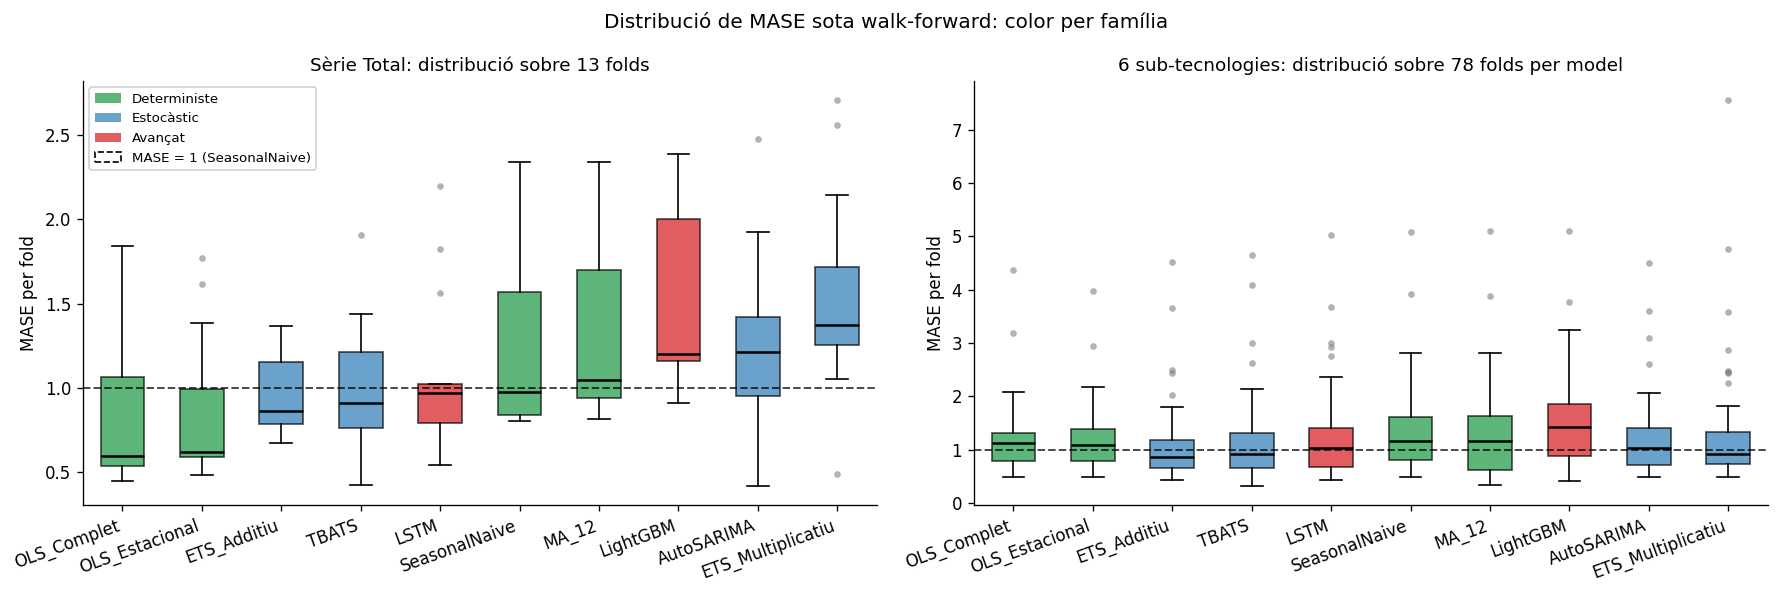

Total: estadístiques MASE (13 folds per model):


,median,mean,std,pct_<1
Model,,,,
OLS_Complet,0.60,0.86,0.50,69.23
OLS_Estacional,0.62,0.86,0.44,76.92
ETS_Additiu,0.86,0.97,0.24,53.85
TBATS,0.91,1.00,0.41,53.85
LSTM,0.97,1.10,0.47,61.54
SeasonalNaive,0.98,1.26,0.57,53.85
MA_12,1.05,1.35,0.58,38.46
LightGBM,1.20,1.50,0.56,15.38
AutoSARIMA,1.21,1.29,0.51,30.77


Sub-tecnologies: estadístiques MASE (78 folds per model):


,median,mean,std,pct_<1
Model,,,,
ETS_Additiu,0.86,1.05,0.66,60.26
ETS_Multiplicatiu,0.92,1.22,1.02,53.85
TBATS,0.93,1.12,0.74,58.97
LSTM,1.02,1.20,0.78,47.44
AutoSARIMA,1.03,1.19,0.69,46.15
OLS_Estacional,1.09,1.18,0.58,41.03
OLS_Complet,1.12,1.16,0.59,43.59
MA_12,1.15,1.25,0.79,44.87
SeasonalNaive,1.17,1.31,0.73,37.18


In [10]:
total_data = wfv_metrics[wfv_metrics['Tecnologia'] == 'Total']
subtech_data = wfv_metrics[wfv_metrics['Tecnologia'] != 'Total']

# Ordre per mediana al Total (que és la pregunta principal)
order_box = total_data.groupby('Model')['MASE'].median().sort_values().index.tolist()
positions = np.arange(len(order_box))
box_colors = [FAMILY_COLOR[FAMILY_OF[m]] for m in order_box]

from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)

# Subplot 1: Total (13 folds per model). Color per família dins de cada caixa.
ax = axes[0]
data_tot = [total_data[total_data['Model'] == m]['MASE'].values for m in order_box]
bp = ax.boxplot(data_tot, positions=positions, widths=0.55, patch_artist=True,
                medianprops=dict(color='black', lw=1.5),
                flierprops=dict(marker='o', markersize=4, markerfacecolor='gray',
                                markeredgecolor='none', alpha=0.6))
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.axhline(1.0, color='black', ls='--', lw=1.2, alpha=0.7, label='MASE=1 (SeasonalNaive)')
ax.set_xticks(positions)
ax.set_xticklabels(order_box, rotation=20, ha='right')
ax.set_ylabel('MASE per fold')
ax.set_title('Sèrie Total: distribució sobre 13 folds', fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Subplot 2: 6 sub-tecnologies (78 folds per model)
ax = axes[1]
data_sub = [subtech_data[subtech_data['Model'] == m]['MASE'].values for m in order_box]
bp2 = ax.boxplot(data_sub, positions=positions, widths=0.55, patch_artist=True,
                 medianprops=dict(color='black', lw=1.5),
                 flierprops=dict(marker='o', markersize=4, markerfacecolor='gray',
                                 markeredgecolor='none', alpha=0.6))
for patch, color in zip(bp2['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.axhline(1.0, color='black', ls='--', lw=1.2, alpha=0.7, label='MASE=1')
ax.set_xticks(positions)
ax.set_xticklabels(order_box, rotation=20, ha='right')
ax.set_ylabel('MASE per fold')
ax.set_title('6 sub-tecnologies: distribució sobre 78 folds per model', fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Llegenda de famílies
family_handles = [Patch(facecolor=FAMILY_COLOR[f], alpha=0.7, label=FAMILY_LABEL[f])
                  for f in FAMILY_ORDER]
family_handles.append(Patch(facecolor='none', edgecolor='black', linestyle='--',
                            label='MASE = 1 (SeasonalNaive)'))
axes[0].legend(handles=family_handles, fontsize=8, loc='upper left', framealpha=0.9)

plt.suptitle('Distribució de MASE sota walk-forward: color per família', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_20_wfv_boxplot.png', bbox_inches='tight')
plt.show()

# Estadístiques de dispersió: Total
disp_tot = (total_data.groupby('Model')['MASE']
            .agg(['median', 'mean', 'std', ('pct_<1', lambda x: (x < 1.0).mean() * 100)])
            .round(2).sort_values('median'))
print('Total: estadístiques MASE (13 folds per model):')
display(disp_tot)

# Estadístiques de dispersió: sub-techs
disp_sub = (subtech_data.groupby('Model')['MASE']
            .agg(['median', 'mean', 'std', ('pct_<1', lambda x: (x < 1.0).mean() * 100)])
            .round(2).sort_values('median'))
print('Sub-tecnologies: estadístiques MASE (78 folds per model):')
display(disp_sub)

### Sèries h=1 per sub-tecnologia (tots els models)

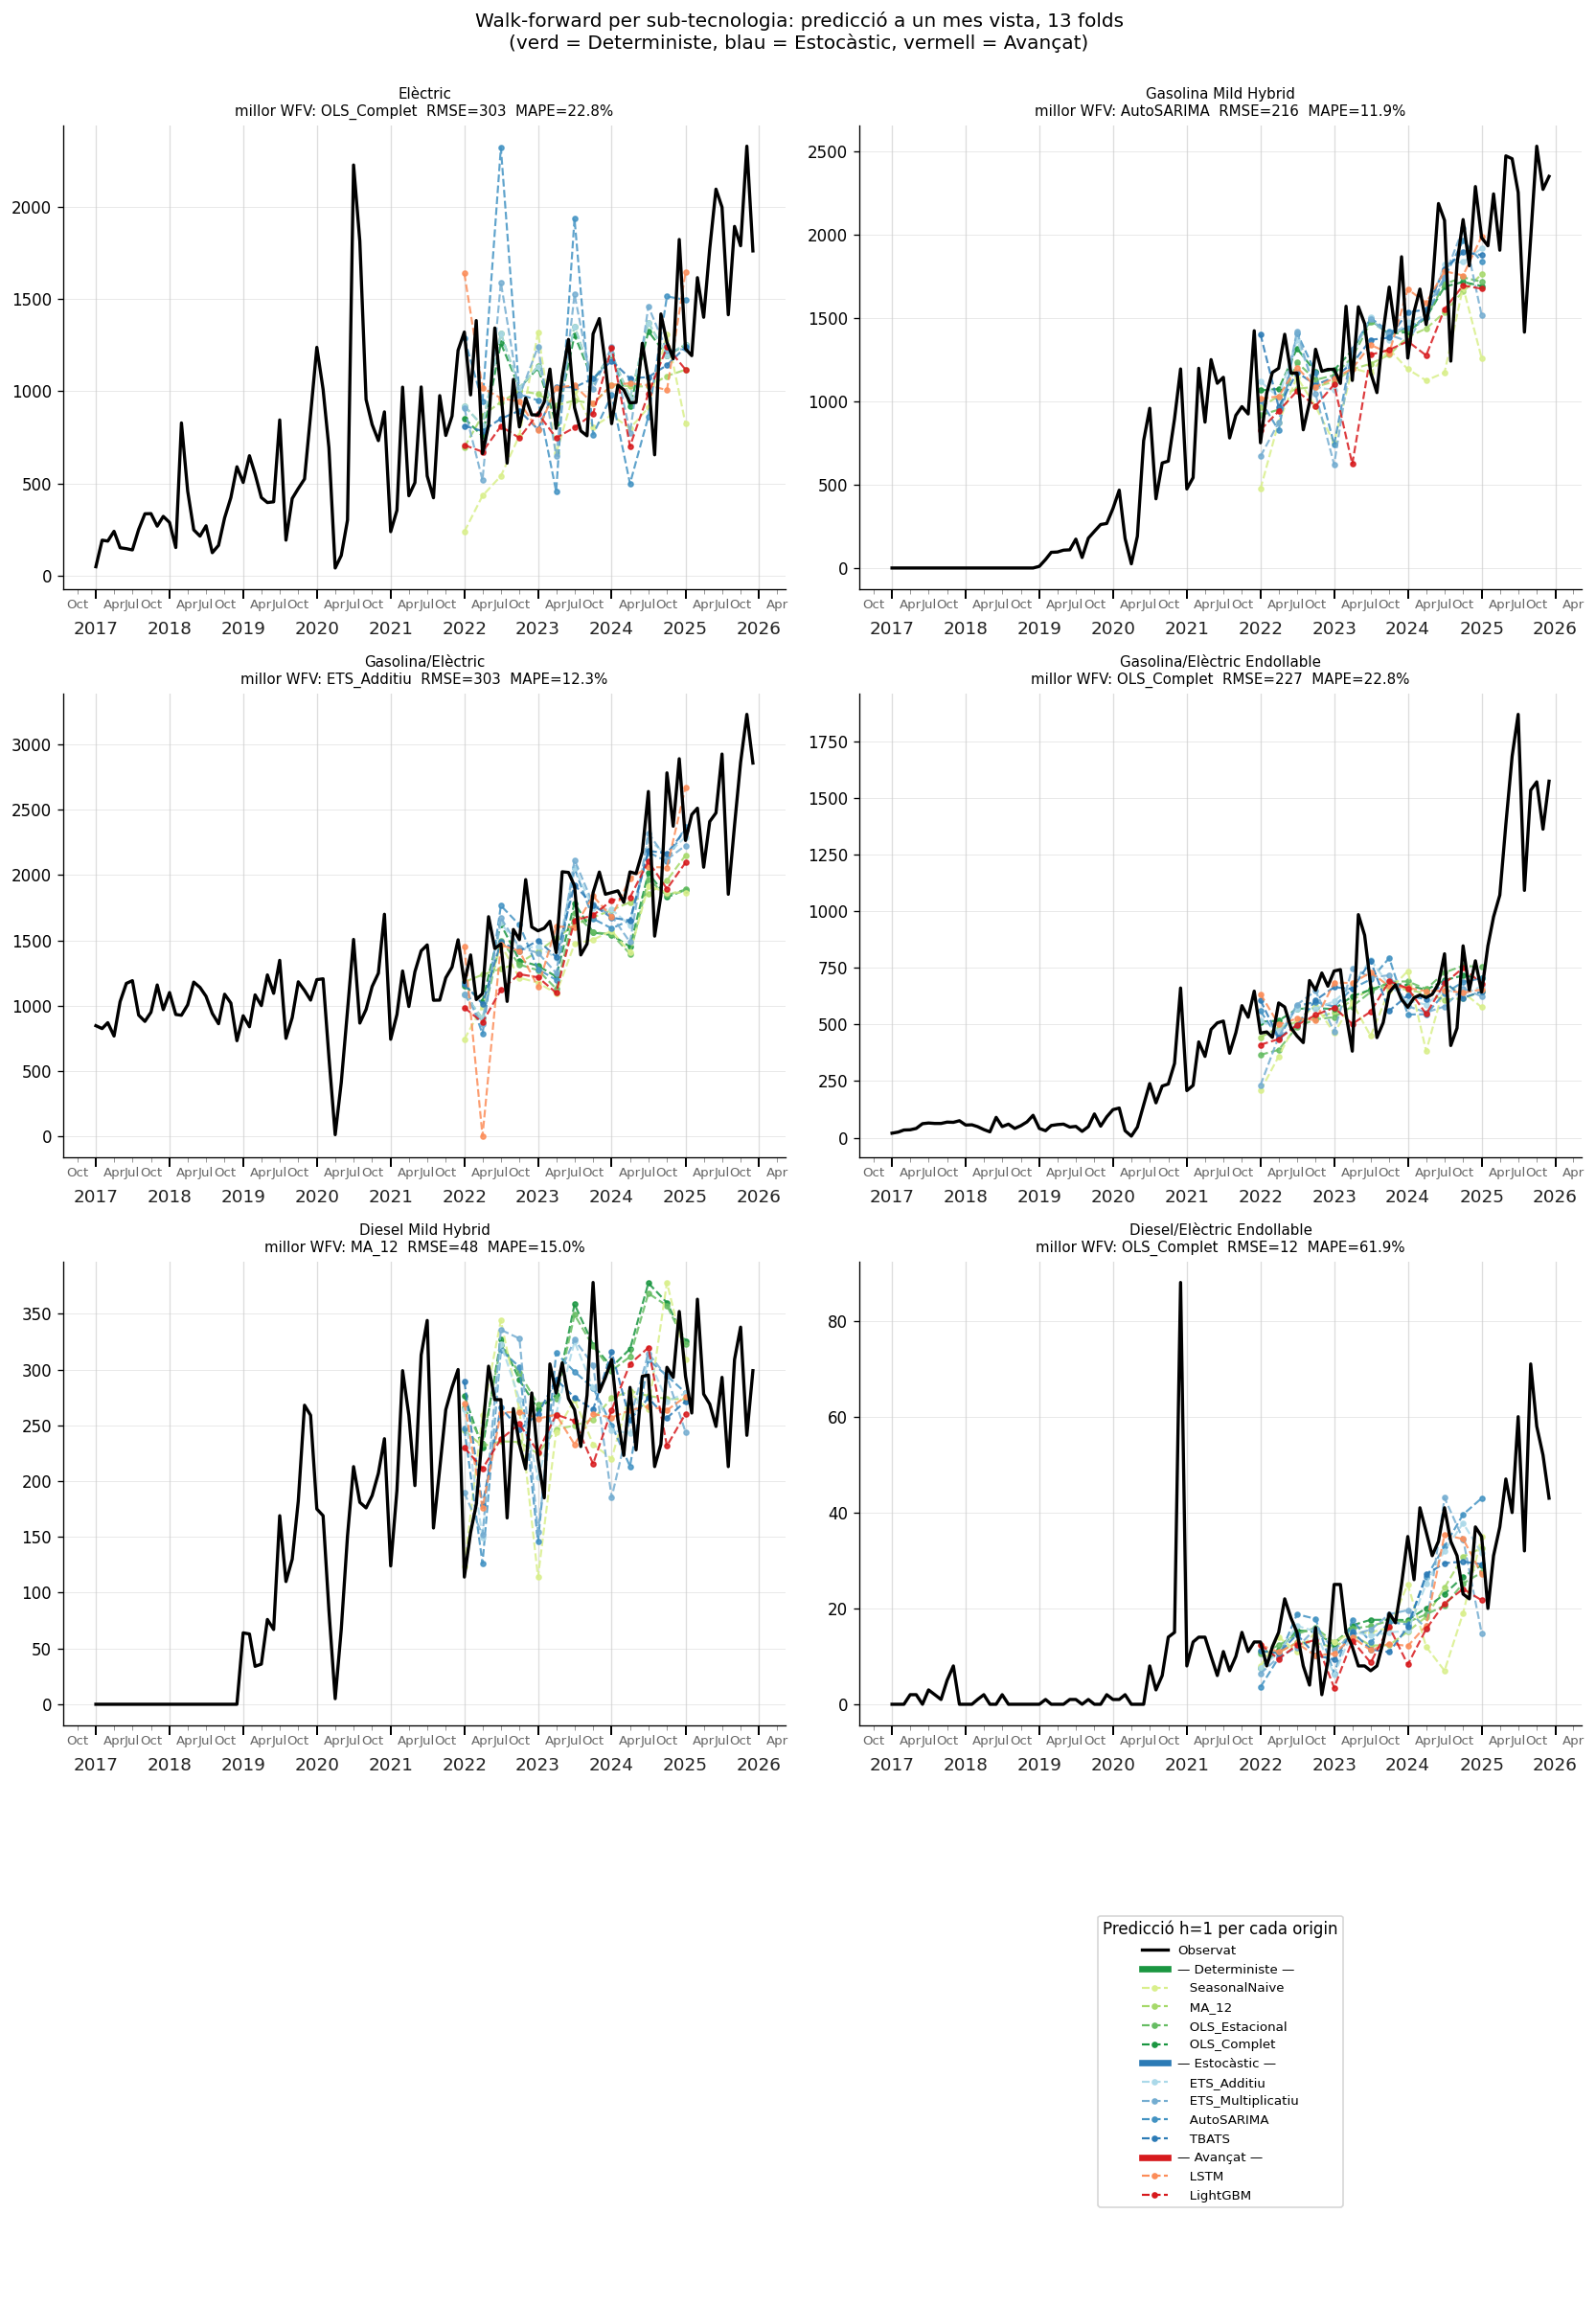

In [11]:
pivot_full_ev = pd.concat([pivot_train_ev, pivot_test_ev]).sort_index()

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    s = pivot_full_ev[tech]
    ax.plot(s.index, s.values, color='black', lw=2, zorder=10)

    sub = wfv_forecasts_raw[
        (wfv_forecasts_raw['Tecnologia'] == tech)
        & (wfv_forecasts_raw['h'] == 1)
    ]
    # Ordenar per família
    models_ordered = sorted(sub['Model'].unique(),
                            key=lambda m: (FAMILY_ORDER.index(FAMILY_OF[m]), m))
    for model_name in models_ordered:
        msub = sub[sub['Model'] == model_name].sort_values('date')
        ax.plot(pd.to_datetime(msub['date']), msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', marker='o', ms=3, alpha=0.85)

    best = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == tech]
            .sort_values('RMSE').iloc[0])
    ax.set_title(
        f'{tech}\nmillor WFV: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
        f'MAPE={best["MAPE"]:.1f}%', fontsize=9)
    format_ts_ax(ax)

# Panells no usats (legend al darrer)
for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend = [Line2D([0], [0], color='black', lw=2, label='Observat')]
for family in FAMILY_ORDER:
    fam_models = [m for m, f in FAMILY_OF.items() if f == family
                  and m in wfv_metrics_agg['Model'].unique()]
    legend.append(Line2D([0], [0], color=FAMILY_COLOR[family], lw=4,
                         label=f'— {FAMILY_LABEL[family]} —'))
    for m in fam_models:
        legend.append(Line2D([0], [0], color=palette[m], lw=1.3, ls='--', marker='o',
                             ms=3, label=f'   {m}'))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=8,
                     title='Predicció h=1 per cada origin')

plt.suptitle('Walk-forward per sub-tecnologia: predicció a un mes vista, 13 folds\n'
             '(verd = Deterministe, blau = Estocàstic, vermell = Avançat)',
             fontsize=12, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_21_wfv_series_per_tech.png', bbox_inches='tight')
plt.show()

### Comparativa per família al Total (figures fig_22, fig_23, fig_24)

Tres figures resumides, una per família, que mostren les prediccions de tots els models de la mateixa família sobre la sèrie Total. Aquestes figures van directament a les seccions 3, 4 i 5 de la memòria (deterministes, estocàstics, avançats).

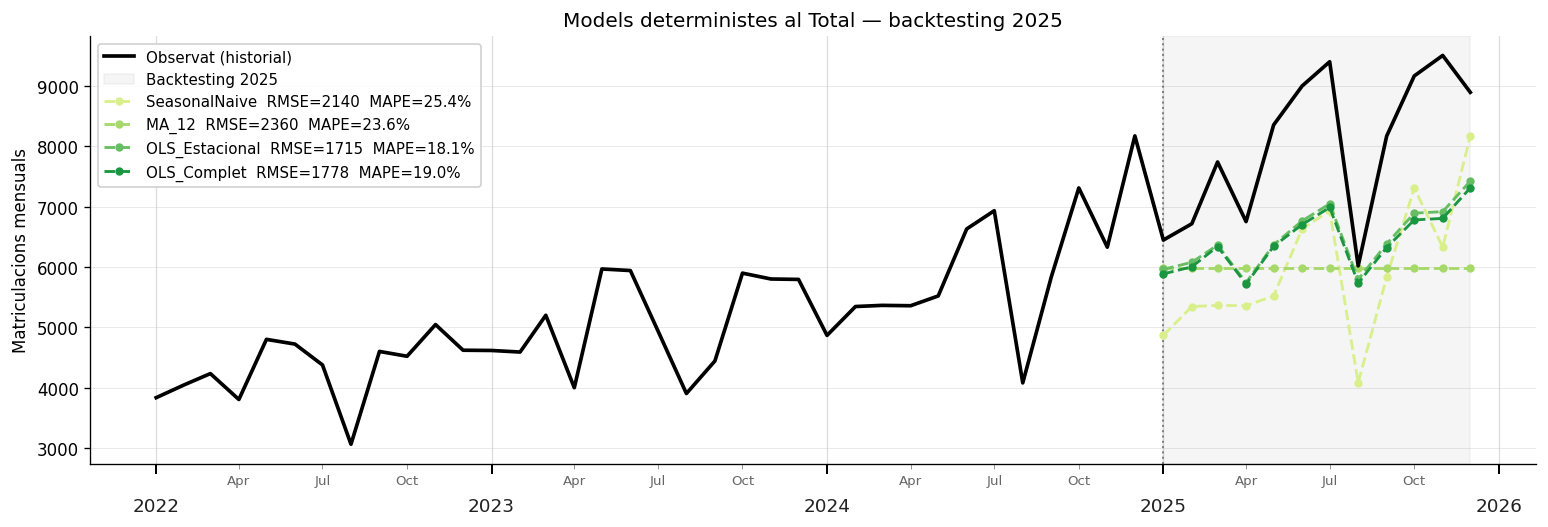

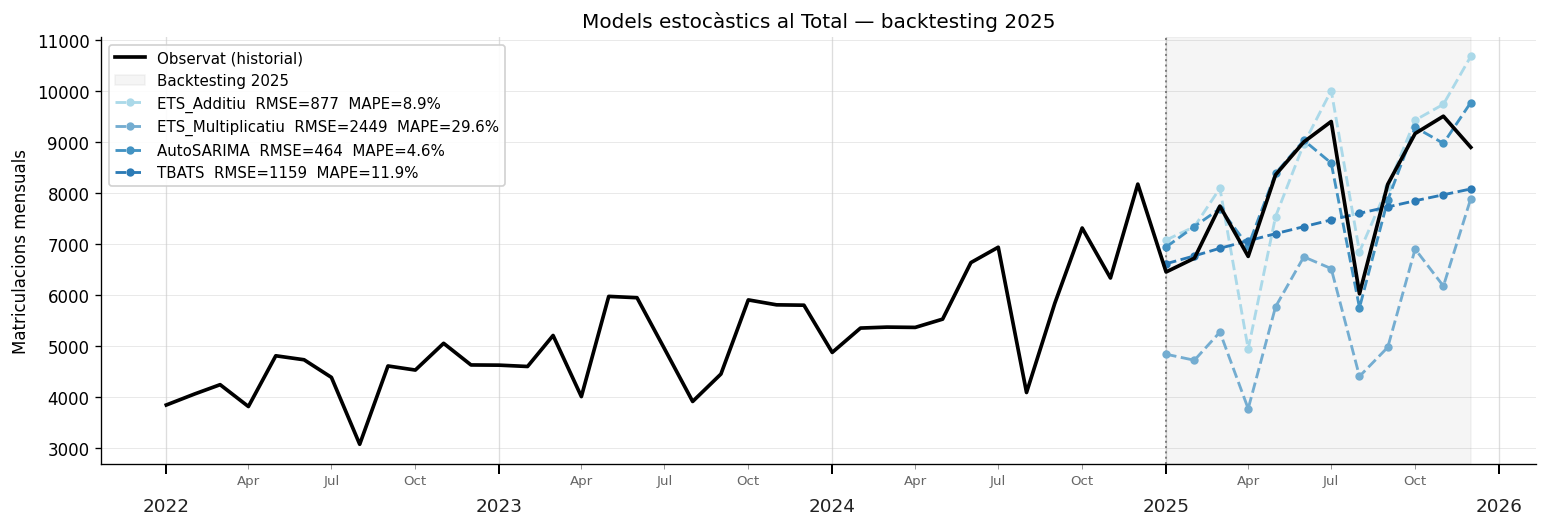

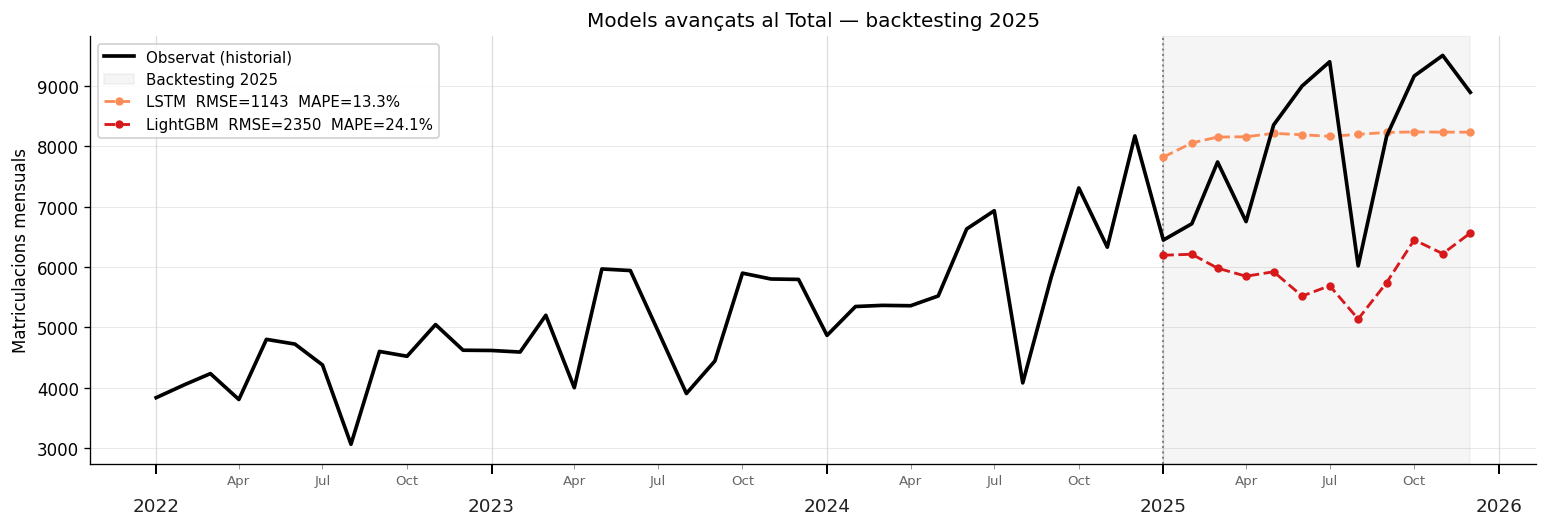

Figures comparatives per família guardades:
  fig_22_deterministic_total.png
  fig_23_stochastic_total.png
  fig_24_advanced_total.png


In [12]:
FAMILY_FIG_INFO = {
    'deterministe': ('fig_22_deterministic_total.png', 'Models deterministes al Total'),
    'estocastic':   ('fig_23_stochastic_total.png',    'Models estocàstics al Total'),
    'avancat':      ('fig_24_advanced_total.png',      'Models avançats al Total'),
}

tech = 'Total'
y_hist = pivot_full_ev[tech].iloc[-48:]
test_start = pivot_test_ev.index[0]
test_end   = pivot_test_ev.index[-1]

for family, (fname, title) in FAMILY_FIG_INFO.items():
    fam_models = [m for m, f in FAMILY_OF.items() if f == family]
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(y_hist.index, y_hist.values, color='black', lw=2.2,
            label='Observat (historial)', zorder=10)
    ax.axvspan(test_start, test_end, alpha=0.08, color='gray', label='Backtesting 2025')
    ax.axvline(test_start, color='gray', ls=':', lw=1.2)

    for m in fam_models:
        msub = all_forecasts[(all_forecasts['Tecnologia'] == tech) &
                             (all_forecasts['Model'] == m)].sort_values('date')
        row = all_metrics[(all_metrics['Model'] == m) &
                          (all_metrics['Tecnologia'] == tech)]
        if len(row):
            lab = f"{m}  RMSE={row['RMSE'].values[0]:.0f}  MAPE={row['MAPE'].values[0]:.1f}%"
        else:
            lab = m
        ax.plot(msub['date'], msub['predicted'],
                color=FAMILY_PALETTE[m], lw=1.7, ls='--', marker='o', ms=4, label=lab)

    ax.set_title(f'{title} — backtesting 2025', fontsize=12)
    ax.set_ylabel('Matriculacions mensuals')
    ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
    format_ts_ax(ax)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / fname, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Figures comparatives per família guardades:')
for f, (fname, _) in FAMILY_FIG_INFO.items():
    print(f'  {fname}')

In [13]:
ranking_total.reset_index().to_csv(RESULTS_DIR / 'model_ranking_total.csv', index=False)
all_metrics.to_csv(RESULTS_DIR / 'all_metrics.csv', index=False)
wfv_metrics.to_csv(RESULTS_DIR / 'all_wfv_metrics.csv', index=False)
wfv_metrics_agg.to_csv(RESULTS_DIR / 'all_wfv_metrics_agg.csv', index=False)
print('Guardats: model_ranking_total.csv, all_metrics.csv, all_wfv_metrics.csv, all_wfv_metrics_agg.csv')

Guardats: model_ranking_total.csv, all_metrics.csv, all_wfv_metrics.csv, all_wfv_metrics_agg.csv


## 5. Conclusions

Aquest projecte estableix un benchmark reproduïble per al forecasting de matriculacions de vehicles electrificats i híbrids a Catalunya entre 2017 i 2025. Hem comparat deu models de tres famílies (deterministes, estocàstics i avançats) sobre set sèries (sis tecnologies més el Total agregat), amb dues avaluacions complementàries: un **holdout únic** sobre el 2025 i un **walk-forward** amb 13 origins. Reportem les mètriques separant explícitament el Total (la pregunta principal: matriculacions agregades) de les sis sub-tecnologies (anàlisi diagnòstica per dinàmica). Discutim els resultats amb RMSE (matrícules/mes) i MAPE (%) per a una lectura directa de la magnitud de l'error; el MAE consta a les taules com a complement quan reforça una comparació, i el MASE el mencionem una sola vegada per a la lectura binària "millor que SeasonalNaive".

### Backtest i walk-forward responen preguntes diferents

El **backtest 2025** estima l'error d'un únic desplegament concret: si haguéssim entrenat amb les dades fins a desembre 2024 i predit els dotze mesos del 2025, quin error real hauríem comès. Té alta variància (una sola realització) i depèn fortament de les peculiaritats d'aquell any. El **walk-forward** simula 13 cicles operatius: re-entrenant cada tres mesos amb la finestra expansiva disponible aleshores i predint els 12 mesos següents, agrega l'error sobre 13 mostres històriques. És substancialment menys sorollós i representa fidelment l'escenari operatiu de tenir el model desplegat amb re-entrenaments periòdics. Per decidir quin model posar en producció el WFV és la mètrica de referència; el backtest 2025 és informatiu del cas concret però no es pot generalitzar.

### Resultat principal: sèrie Total

Al **backtest 2025**, AutoSARIMA guanya clarament amb MAPE 4.6% i RMSE 464 matrícules/mes, seguit d'ETS Additiu (MAPE 8.9%, RMSE 877). Tots dos entrenen sobre el logaritme del Total (la transformació recomanada per l'EDA amb BoxCox λ≈0.49 per estabilitzar la variança creixent de l'agregat). La diferència respecte a TBATS i LSTM (MAPE 11.9% i 13.3%, RMSE 1.159 i 1.143) demostra que en aquesta sèrie l'escala de modelització pesa més que la família del model. Els deterministes regressius queden al mig de la taula (OLS_Estacional MAPE 18.1% i RMSE 1.715, OLS_Complet 19.0% i 1.778): millors que els naives però lluny dels líders log-transformats al cicle 2025. Lectura binària: tots dos líders baten còmodament el SeasonalNaive del 2025 (MASE 0.42 i 0.77 < 1), mentre que els models de la cua tenen MASE > 2 i són pitjor que la regla naive del "any anterior".

Sota **walk-forward**, però, el rànquing es reordena del tot: **OLS_Estacional i OLS_Complet empaten al primer lloc amb MAPE mig 12% i RMSE proper a 860 matrícules/mes**, seguits d'ETS Additiu (MAPE 15.7%, RMSE 979), TBATS (MAPE 15.2%, RMSE 1.046) i LSTM (MAPE 15.9%, RMSE 1.122). AutoSARIMA cau al setè lloc (MAPE 21.2%, RMSE 1.336), per darrere fins i tot del Seasonal Naive (MAPE 17.7%, RMSE 1.204), i ETS Multiplicatiu i LightGBM tanquen el rànquing (MAPE 22.1% i 20.9%, RMSE 1.441 i 1.494). Aquesta divergència no és contradicció sinó informació útil: la log-transformació d'AutoSARIMA és molt efectiva al cicle del 2025 (un any de creixement excepcional, +34% YoY front al +17% històric) però fràgil al llarg dels altres dotze cicles del walk-forward, on una regressió lineal amb dummies mensuals (OLS_Estacional) ja és més robusta que qualsevol model estocàstic complex.

La recomanació de producció és **OLS_Estacional**: lidera el WFV amb el mínim absolut (MAPE 12.0%, RMSE 857 matrícules/mes), és el model més simple i interpretable del benchmark, i el seu cost computacional és negligible. ETS Additiu queda com a segona opció raonable (3r al WFV amb MAPE 15.7%, 2n al backtest amb MAPE 8.9%) per a qui prefereixi un model estocàstic clàssic. AutoSARIMA és l'opció més arriscada: pot ser brillant en cicles de creixement fort com el 2025 (MAPE 4.6%) però poc consistent a la resta, vàlida només si s'accepta la variabilitat operativa.

### Anàlisi per sub-tecnologia

Cap model guanya a totes les sis sub-tecnologies. Sota **WFV**, els deterministes regressius guanyen o empaten quatre de sis sèries: a Elèctric empaten amb ETS Additiu, a Diesel Mild Hybrid MA_12 lidera, i a Gasolina/Elèctric Endollable i Diesel/Elèctric Endollable OLS_Complet lidera. ETS Additiu manté el lideratge a Gasolina/Elèctric, i AutoSARIMA a Gasolina Mild Hybrid. Al backtest 2025 el patró és diferent: ETS Multiplicatiu guanya dues sèries amb estacionalitat creixent (Elèctric MAPE 22.0% i RMSE 494, Gasolina/Elèctric MAPE 6.2% i RMSE 189), AutoSARIMA dues amb dinàmica més estable (Gasolina Mild Hybrid MAPE 7.7% i RMSE 199, Diesel/Elèctric Endollable MAPE 28.9% i RMSE 16) i LSTM Diesel Mild Hybrid per centèsimes (MAPE 11.3%, RMSE 49).

Una advertència sobre el backtest: amb només 12 observacions de test per sèrie, les diferències petites no són estadísticament distingibles. A Diesel Mild Hybrid LSTM, TBATS i AutoSARIMA són empat efectiu (MAPE entre 11.3% i 12.1%, RMSE entre 43 i 51); a Gasolina/Elèctric AutoSARIMA i ETS Additiu empaten també (MAPE 7.0% i 7.2%, RMSE pràcticament idèntic). Per identificar quina família funciona millor a cada dinàmica confiem més en el patró del WFV, que agrega sobre 78 folds per sub-tecnologia (6 sèries × 13 origins) i té molta menys variància; el patró WFV reforça la lectura del Total: els deterministes són sorprenentment competitius.

### Límits del benchmark

Primer, amb N=96 mostres al train del backtest (entre 60 i 96 sota WFV) i una estacionalitat anual neta, els estocàstics clàssics i fins i tot els deterministes superen el machine learning en ambdues avaluacions, replicant Makridakis et al. (2020) i reforçant el principi de simplicitat: una OLS amb dummies mensuals i tendència lineal lidera el WFV del Total i guanya o empata a quatre de sis sub-tecnologies. LightGBM tanca el rànquing del Total al backtest (MAPE 24.1%, RMSE 2.350) i és penúltim al WFV (MAPE 20.9%, RMSE 1.494); LSTM és mediocre malgrat la seva flexibilitat. Segon, el creixement del +34% YoY al 2025 reflecteix una acceleració estructural del mercat que cap sèrie univariant pot anticipar: els drivers (xarxa de càrrega, preus dels EV, política industrial) són exògens al senyal històric.

### El cas extrem: PHEV (Gasolina/Elèctric Endollable)

Tots els models tenen MAPE entre 36% i 46% i RMSE entre 585 i 746 matrícules/mes al backtest 2025. La dinàmica no depèn només de l'existència del MOVES III, que ja portava quatre anys actiu, sinó del **règim regulatori canviant del programa**. El plateau del 2024 (−1%) coincideix amb la incertesa sobre la pròrroga del pla, que originalment vencia el 31 de desembre de 2024. El salt del +101.7% al 2025 s'explica per una combinació de factors regulatius: la pròrroga aprovada per Reial Decret-llei a l'abril amb efecte retroactiu des de gener, l'ampliació pressupostària a 800 milions d'euros, els ajuts directes de fins a 4.500€ per PHEV, la deducció del 15% a l'IRPF, i l'efecte de la data límit del 31 de desembre que va resoldre massivament les sol·licituds pendents. Cap d'aquests senyals existeix a la sèrie temporal univariant; són exclusivament regulatoris. El WFV ja revela la dificultat estructural: OLS_Complet millora fins a un MAPE proper al 33% i RMSE 511 matrícules/mes perquè la regressió lineal s'adapta repetidament al règim canviant sota diversos folds, però segueix sent la sèrie més difícil del benchmark.

### Línia natural de continuïtat

A `models/stochastic/sarima.ipynb` ja vam provar una variant **SARIMAX amb dummies de COVID i MOVES III**: durant 2025, però, aquestes dues dummies són constants (COVID = 0 perquè la pandèmia ja s'havia tancat; MOVES III = 1 perquè el pla portava quatre anys actiu sense interrupció), de manera que les prediccions resulten pràcticament idèntiques a AutoSARIMA i no aporten valor. La conclusió no és que SARIMAX no serveixi, sinó que aquestes dues dummies són massa gruixudes per capturar la dinàmica del 2025.

La via concreta per estendre el benchmark amb informació regulatòria útil és substituir aquestes dummies per **indicadors molt més específics del règim del MOVES III**: una dummy pulse al desembre 2024 (efecte data límit del 31-des-2024), una dummy step des d'abril 2025 (vigència del Reial Decret-llei d'abril 2025 amb efecte retroactiu), o fins i tot l'import de pressupost mensual disponible quan es pugui aconseguir. Aplicades especialment a Gasolina/Elèctric Endollable, aquestes variables podrien capturar el plateau del 2024 i el salt del +101.7% del 2025 que els models univariants (i la SARIMAX bàsica que ja vam provar) no detecten. Per al Total i altres sèries, regressors d'infraestructura de càrrega i preus dels EV permetrien capturar l'acceleració estructural del 2025. Opcionalment, un pas de reconciliació jeràrquica garantiria que les prediccions per sub-tecnologia sumin coherentment al Total. Amb aquestes extensions, el projecte passaria de respondre què diuen les dades sobre el passat a anticipar canvis impulsats per polítiques i mercat.